<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ DSC LOGIKA UI 2026: Credit Risk dengan GBDT dan Rantai Markov ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Prediksi gagal bayar DPD 90+ dalam 12 bulan pada pinjaman konsumen Indonesia</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **IndomaretLabtekV**

### DSC0052

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Pemuatan Data dan Audit Integritas**](#3)
4. [**Rekayasa Fitur**](#4)
5. [**Analisis Data Eksploratif**](#5)
6. [**Strategi Validasi**](#6)
7. [**Pemodelan**](#7)
8. [**Analisis Kesalahan dan Ensemble**](#8)
9. [**Riwayat Eksperimen dan Pemilihan Model**](#9)
10. [**Inferensi dan Submisi**](#10)
11. [**Pasca-Analisis**](#11)
12. [**Daftar Pustaka**](#12)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Lembaga pembiayaan konsumen perlu mengenali pengajuan pinjaman yang berpotensi bermasalah sebelum dana dicairkan, hanya dengan informasi yang tersedia saat keputusan diambil. Pada kompetisi **DSC LOGIKA UI 2026**, peserta diminta membangun model yang memberi skor risiko untuk setiap aplikasi pinjaman. Sebuah pinjaman dianggap mengalami kesulitan bayar serius bila *Days Past Due* (DPD) akhir harinya mencapai 90 atau lebih dalam 12 bulan kalender sesudah pencairan.

- **Tugas**: klasifikasi biner dengan keluaran skor peluang `default_probability`
- **Target**: `target = 1` bila pinjaman mencapai DPD 90+ dalam 12 bulan, `0` bila tidak
- **Metrik**: statistik Kolmogorov-Smirnov (KS)
- **Penilaian babak penyisihan**: 45% *public score*, 45% *private score*, 10% reprodusibilitas *notebook*
- **Batasan**: hanya data panitia, tanpa data eksternal, dan hanya informasi sebelum `decision_datetime`
- **Platform**: Kaggle Notebook, GPU T4 x2

---

## Dataset

*Dataset* berbentuk relasional: satu tabel aplikasi terpilih per customer, ditambah enam tabel riwayat yang terhubung lewat `customer_id`. Semua nilai uang dalam Rupiah dan seluruh *timestamp* memakai waktu Asia/Jakarta. Kolom `decision_datetime` adalah batas informasi: fitur hanya boleh memakai kejadian sebelum titik ini.

| Tabel | Baris | Isi |
|---|---:|---|
| `train_applications` | 70.000 | Aplikasi terpilih beserta `target` |
| `test_applications` | 30.000 | Aplikasi yang harus diprediksi |
| `customer_profiles` | 100.000 | Demografi, pekerjaan, pendapatan, tanggungan, tempat tinggal |
| `previous_applications` | 201.984 | Riwayat pengajuan pinjaman beserta keputusannya |
| `repayment_history` | 1.361.341 | Cicilan per pinjaman lama: jatuh tempo, pembayaran, DPD |
| `account_behavior` | 1.084.418 | Ringkasan rekening bulanan: saldo, arus masuk dan keluar |
| `bureau_observations` | 797.563 | Laporan biro kredit: skor, utilisasi, *inquiry*, tunggakan |
| `ecommerce_transactions` | 4.359.817 | Item belanja *online*: kategori, harga, metode bayar, status |

Tingkat gagal bayar di *train* adalah 13,58%. Sebanyak 30% aplikasi berasal dari customer tanpa riwayat pinjaman, sehingga customer ini hanya punya data aplikasi, biro, dan *e-commerce*.

---

## Metrik

KS mengukur jarak vertikal terbesar antara distribusi kumulatif skor kelas gagal bayar ($F_1$) dan kelas lancar ($F_0$):

$$\text{KS} = \max_s \left| F_1(s) - F_0(s) \right|$$

Metrik ini hanya bergantung pada urutan skor, bukan nilai absolutnya. Akibatnya kalibrasi global tidak mengubah skor, dan rata-rata *rank* antarmodel aman dipakai sebagai cara *blending*. KS juga ditentukan oleh satu titik potong, jadi kesalahan yang mahal adalah salah urut di sekitar titik tersebut.

---

## Pendekatan: Enam GBDT Global + Rantai Markov *Repayment*

Pendekatan final (v72) memakai tiga keluarga *gradient boosted decision tree* (GBDT): LightGBM (Ke dkk., 2017), XGBoost (Chen & Guestrin, 2016), dan CatBoost (Prokhorenkova dkk., 2018). Masing-masing dipakai dalam dua konfigurasi: standar dan dangkal (sufiks `_s`). Keenam model membaca 242 fitur yang dibangun dari tujuh tabel, termasuk 10 fitur rantai Markov yang memodelkan transisi status telat bayar per customer.

```
Delapan tabel mentah (cutoff decision_datetime)
    |
    +-- Pipeline fitur per tabel            [232 kolom]
    +-- Rantai Markov repayment (5 status)   [10 kolom]
         |
    Matriks fitur 70.000 train + 30.000 test  [242 kolom]
         |
    LightGBM | LightGBM_s | XGBoost | XGBoost_s | CatBoost | CatBoost_s
         |   StratifiedKFold 5 fold x 3 split seed = 15 booster per model
         |   90 booster total
    Rata-rata probabilitas per model
         |
    Rata-rata rank enam model (bobot sama) -> default_probability
```

Tidak ada bobot *blend* yang dituning, tidak ada *stacking*, dan tidak ada *postprocessing*. Resep enam model sudah dikunci sejak v22, sebelum blok Markov ditambahkan, sehingga pemilihannya tidak bergantung pada OOF akhir.

---

## Ringkasan Temuan

| Temuan | Konsekuensi |
|---|---|
| Telat bayar berbentuk rantai: *hazard* 0,14 sesudah bayar tepat waktu, 0,71 sesudah satu kali telat | Blok Markov per customer, *public* +0,005 |
| Level harga belanja adalah sinyal risiko lintas kanal, juga untuk customer tanpa riwayat | Fitur `pp_*`, *public* +0,016 |
| Perubahan struktur model menaikkan OOF tetapi menurunkan *public* | Resep tetap enam pohon global |
| Pada enam file era Markov, korelasi OOF dengan *public* adalah -0,89 | OOF tertinggi tidak dipakai sebagai penentu tunggal |
| Tabel sudah dipotong panitia di `decision_datetime` | Audit *look-ahead* bersih, *cutoff* tetap diterapkan ulang |
| *Test* adalah split acak, AUC adversarial 0,501 | `StratifiedKFold` mewakili *test* |

| Kandidat | OOF KS | *Public* KS |
|---|---:|---:|
| **v72 (final)** | **0,52580** | **0,56822** |
| Enam GBDT tanpa Markov (v39a) | 0,52448 | 0,56337 |
| OOF tertinggi, pohon per segmen + MLP (v75 recipe C) | 0,52861 | 0,56374 |

---

## Referensi Utama

- [docs/context.md](docs/context.md) -- deskripsi kompetisi, aturan, dan format submisi
- [handoff/2026-10-30/README.md](handoff/2026-10-30/README.md) -- serah terima jalur Markov, model per segmen, dan MLP
- [research/autoresearch/findings.md](research/autoresearch/findings.md) -- temuan riset dan protokol yang dikunci sebelum hasil

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

*Notebook* ini dijalankan di Kaggle dengan dua GPU Tesla T4. XGBoost dan CatBoost memakai GPU saat pelatihan, sedangkan LightGBM dan seluruh inferensi berjalan di CPU. Satu kali *Run All* dalam mode `end_to_end` tercatat selama 1.714 detik (sekitar 28,5 menit), dengan 1.575 detik di antaranya untuk melatih 90 *booster*.

In [1]:
!nvidia-smi

Fri Oct 30 17:37:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

> Catatan untuk juri dan panitia: *notebook* ini dijalankan dalam mode `Settings.RUN_MODE = 'end_to_end'`, yaitu membangun fitur dari CSV mentah, melatih 90 *booster*, lalu menulis `submission.csv`. Cukup pasang dataset kompetisi dan jalankan *Run All* dengan akselerator GPU T4. Mode `'inference'` melewati pelatihan dan memuat *booster* dari `v72_bundle` yang terverifikasi SHA256; mode ini membutuhkan *bundle* terpasang sebagai *input* atau `ARTIFACT_URL` terisi.

---

## Instalasi

Baris berikut memasang versi pustaka yang sama dengan saat artefak dibuat. Peringatan *dependency resolver* tentang `cudf-polars-cu12` tidak berpengaruh karena *notebook* ini tidak memakai `cudf`.

In [2]:
%pip install -q polars==2.0.0 lightgbm==4.7.0 xgboost==3.4.1 catboost==1.2.10 pyarrow gdown

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-polars-cu12 26.2.1 requires polars<1.36,>=1.30, but you have polars 2.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


---

## Pustaka

Seluruh impor dikelompokkan dalam satu sel. Polars menangani agregasi tabel besar (sampai 4,4 juta baris *e-commerce*) dengan cepat, pandas dipakai sebagai format masukan model, sedangkan LightGBM, XGBoost, dan CatBoost menjadi tiga keluarga model. SciPy menyediakan `ks_2samp` untuk metrik dan `rankdata` untuk *blending*.

In [3]:
import hashlib
import json
import math
import os
import random
import time
import zipfile
from pathlib import Path

import gdown
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
from scipy.stats import ks_2samp, rankdata, spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

---

## Settings

Kelas `Settings` memusatkan konfigurasi: tiga *split seed* (42, 7, 2026), daftar enam model, mode jalan, perangkat untuk XGBoost dan CatBoost, serta jalur data dan keluaran. Fungsi `find_dir` mencari `train_applications.csv` di `/kaggle/input` lalu di folder lokal, sehingga *notebook* berjalan tanpa mengubah jalur. Ubah `RUN_MODE` menjadi `'inference'` untuk melewati pelatihan, atau `XGB_DEVICE = 'cpu'` dan `CAT_PARAMS = {'task_type': 'CPU'}` bila GPU tidak tersedia.

In [4]:
def find_dir(roots, marker):
    for root in roots:
        hits = sorted(Path(root).rglob(marker)) if Path(root).exists() else []
        if hits:
            return hits[0].parent
    return None


class Settings:
    SEED = 42
    N_FOLDS = 5
    TARGET = 'target'
    ID_COL = 'application_id'
    SEEDS = [42, 7, 2026]
    SIX = ['lgb', 'lgb_s', 'xgb', 'xgb_s', 'cat', 'cat_s']
    RUN_MODE = 'end_to_end'
    XGB_DEVICE = 'cuda'
    CAT_PARAMS = {'task_type': 'GPU', 'devices': '0'}
    THREADS = 2
    ARTIFACT_URL = ''
    INPUT_ROOTS = ['/kaggle/input', '../data', 'data', '.']
    BUNDLE_ROOTS = ['/kaggle/input', '../artifacts/v72_bundle', 'v72_bundle']
    DATA_DIR = find_dir(INPUT_ROOTS, 'train_applications.csv')
    OUTPUT_DIR = Path('/kaggle/working/v72_final') if Path('/kaggle/working').exists() else Path('../results/v72_final')


CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('data', CFG.DATA_DIR, 'output', CFG.OUTPUT_DIR)
for lib in (pl, lgb, xgb):
    print(lib.__name__, lib.__version__)

data /kaggle/input/competitions/data-science-competition-logika-ui-2026 output /kaggle/working/v72_final
polars 2.0.0
lightgbm 4.7.0
xgboost 3.4.1


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan Python dan NumPy. Setiap *booster* juga menerima *seed*-nya sendiri lewat parameter model. Pelatihan GPU tetap dapat menghasilkan selisih numerik kecil antareksekusi karena urutan reduksi paralel di *hardware*.

In [5]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)


seed_everything(CFG.SEED)

---

## Muat Artefak

Pada mode `inference`, sel ini mencari folder artefak yang sudah terbuka, lalu `v72_bundle.zip` yang terpasang sebagai *dataset*, lalu unduhan dari `ARTIFACT_URL`. SHA256 setiap berkas diverifikasi terhadap `manifest.json`, dan berkas yang berubah menghentikan *notebook*. Pada mode `end_to_end`, sel ini hanya menyiapkan folder `run/` untuk prediksi OOF, prediksi *test*, log, dan 90 *booster* hasil pelatihan.

In [6]:
def file_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


if CFG.RUN_MODE == 'inference':
    CFG.ARTIFACT_DIR = find_dir(CFG.BUNDLE_ROOTS, 'manifest.json')
    if CFG.ARTIFACT_DIR is None:
        CFG.ARTIFACT_DIR = CFG.OUTPUT_DIR / 'v72_bundle'
        zip_dir = find_dir(CFG.BUNDLE_ROOTS[:1], 'v72_bundle.zip')
        archive = zip_dir / 'v72_bundle.zip' if zip_dir else CFG.OUTPUT_DIR / 'v72_bundle.zip'
        if not zip_dir:
            gdown.download(CFG.ARTIFACT_URL, str(archive), fuzzy=True)
        with zipfile.ZipFile(archive) as z:
            z.extractall(CFG.ARTIFACT_DIR)
    manifest = json.loads((CFG.ARTIFACT_DIR / 'manifest.json').read_text())
    for rel, digest in manifest['files'].items():
        assert file_sha(CFG.ARTIFACT_DIR / rel) == digest, rel
    print('artefak terverifikasi:', len(manifest['files']), 'berkas di', CFG.ARTIFACT_DIR)
    CFG.PRED_DIR, CFG.REFIT_DIR, CFG.MODEL_DIR = CFG.ARTIFACT_DIR / 'kernel', CFG.ARTIFACT_DIR / 'refit', CFG.ARTIFACT_DIR / 'models'
else:
    CFG.PRED_DIR = CFG.REFIT_DIR = CFG.OUTPUT_DIR / 'run'
    CFG.MODEL_DIR = CFG.PRED_DIR / 'models'
    CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)
    print('mode end_to_end, keluaran di', CFG.PRED_DIR)

mode end_to_end, keluaran di /kaggle/working/v72_final/run


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemuatan Data dan Audit Integritas <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Sebelum membangun fitur, delapan tabel dibaca dan diaudit. Fokus audit adalah dua risiko terbesar pada data kredit: duplikasi unit observasi dan kebocoran informasi dari masa sesudah keputusan.

## Ukuran Tabel

Delapan tabel dibaca dari CSV dengan Polars. Urutan ID pada `sample_submission` disimpan sebagai acuan urutan baris berkas submisi.

In [7]:
TABLES = ['train_applications', 'test_applications', 'customer_profiles', 'previous_applications',
          'repayment_history', 'account_behavior', 'bureau_observations', 'ecommerce_transactions']
tables = {t: pl.read_csv(CFG.DATA_DIR / f'{t}.csv', try_parse_dates=True, infer_schema_length=100000) for t in TABLES}
sample = pl.read_csv(CFG.DATA_DIR / 'sample_submission.csv').select('application_id')
print(pl.DataFrame({'table': TABLES, 'rows': [tables[t].height for t in TABLES], 'columns': [tables[t].width for t in TABLES]}))

shape: (8, 3)
┌────────────────────────┬─────────┬─────────┐
│ table                  ┆ rows    ┆ columns │
│ ---                    ┆ ---     ┆ ---     │
│ str                    ┆ i64     ┆ i64     │
╞════════════════════════╪═════════╪═════════╡
│ train_applications     ┆ 70000   ┆ 10      │
│ test_applications      ┆ 30000   ┆ 9       │
│ customer_profiles      ┆ 100000  ┆ 8       │
│ previous_applications  ┆ 201984  ┆ 11      │
│ repayment_history      ┆ 1361341 ┆ 9       │
│ account_behavior       ┆ 1084418 ┆ 10      │
│ bureau_observations    ┆ 797563  ┆ 14      │
│ ecommerce_transactions ┆ 4359817 ┆ 10      │
└────────────────────────┴─────────┴─────────┘


> ### Insights
> Tabel riwayat jauh lebih besar dari tabel aplikasi: rata-rata sekitar 44 baris *e-commerce*, 14 cicilan, 11 bulan rekening, dan 8 laporan biro per customer. Seluruh informasi ini harus diringkas menjadi satu baris per aplikasi, sehingga kualitas agregasi lebih menentukan skor daripada pilihan model.

---

## Integritas dan Audit Kebocoran

Pemeriksaan berikut menghitung ID ganda, customer yang muncul di *train* dan *test*, serta peristiwa sesudah keputusan. Audit *repayment* membandingkan DPD terbesar setiap cicilan dengan jarak hari dari jatuh tempo ke keputusan: DPD yang lebih besar dari jarak itu berarti tabel memuat informasi masa depan.

In [8]:
train, test = tables['train_applications'], tables['test_applications']
apps = pl.concat([train.select('customer_id', 'decision_datetime'), test.select('customer_id', 'decision_datetime')])
gap = (tables['repayment_history'].join(apps, on='customer_id').with_columns(gap=(pl.col('decision_datetime').cast(pl.Datetime) - pl.col('due_date').cast(pl.Datetime)).dt.total_seconds() / 86400))
checks = {
    'application_id ganda train': train.height - train['application_id'].n_unique(),
    'application_id ganda test': test.height - test['application_id'].n_unique(),
    'customer ganda': apps.height - apps['customer_id'].n_unique(),
    'customer train di test': train.join(test, on='customer_id', how='semi').height,
    'cicilan jatuh tempo sesudah keputusan': gap.filter(pl.col('gap') < 0).height,
    'DPD melewati jarak ke keputusan': gap.filter(pl.col('max_days_past_due') > pl.col('gap')).height,
}
for k, v_ in checks.items():
    print(f'{k:40s} {v_}')
print('bad rate train', round(train['target'].mean(), 5))

application_id ganda train               0
application_id ganda test                0
customer ganda                           0
customer train di test                   0
cicilan jatuh tempo sesudah keputusan    0
DPD melewati jarak ke keputusan          0
bad rate train 0.13581


> ### Insights
> Tidak ada ID ganda, tidak ada customer yang muncul di *train* dan *test*, dan tidak ada DPD yang melampaui jarak waktu ke keputusan. Kolom seperti `max_days_past_due` berpotensi membocorkan masa depan bila tabel diambil sesudah keputusan, tetapi audit menunjukkan panitia sudah memotongnya.
>
> Setiap customer hanya punya satu aplikasi terpilih, jadi unit independen adalah customer dan tidak ada grup yang bisa terbelah antar-*fold*. *Cutoff* `decision_datetime` tetap diterapkan ulang di setiap pembentuk fitur sebagai pengaman.

---

## Fungsi Metrik

Implementasi KS yang dipakai di seluruh *notebook* sama dengan kode evaluasi panitia: `ks_2samp` antara skor kelas positif dan kelas negatif.

In [9]:
def ks(y, p):
    return float(ks_2samp(p[y == 1], p[y == 0]).statistic)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Rekayasa Fitur <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini membangun 242 fitur per aplikasi dari tujuh tabel. Analisis eksploratif di bagian 5 dilakukan sesudah fitur terbentuk karena observasinya memakai fitur yang sama dengan model.

## Prinsip Anti-Kebocoran

Semua pembentuk fitur mengikuti aturan yang sama agar model hanya melihat informasi yang tersedia saat keputusan:

- **Cutoff per tabel**: cicilan dipakai bila `due_date <= decision_datetime`, laporan biro bila `available_datetime <= decision_datetime`, dan transaksi bila `transaction_datetime <= decision_datetime`
- **Bulan rekening yang sudah selesai**: baris `account_behavior` hanya dipakai bila bulan kalendernya berakhir sebelum keputusan
- **Deduplikasi order**: `order_total` berulang di setiap item, jadi order diringkas ke satu baris sebelum agregasi
- **Tanpa label**: tidak ada *target encoding*, dan referensi harga per kategori hanya memakai bulan sebelum bulan keputusan
- **Urutan deterministik**: seri diurutkan dengan pemutus seri (`loan_id`, `bureau_observation_id`) agar hasil sama di setiap eksekusi

---

## Pipeline Fitur per Tabel

Setiap fungsi menghasilkan satu baris per customer, lalu `build_all` menggabungkannya dan menambah rasio lintas tabel. Prefiks kolom menunjukkan sumbernya:

| Famili | Prefiks | Jumlah | Contoh sinyal |
|---|---|---:|---|
| Aplikasi dan rasio lintas tabel | tanpa prefiks | 26 | `dti_total`, `income_verif_ratio`, `has_history` |
| Biro kredit | `bc_`, `bh_`, `bp_`, `bz_` | 50 | skor per *provider*, tren skor, *inquiry* eksternal |
| *E-commerce* | `ec_`, `ec2_` | 40 | akselerasi order 30 hari, pembatalan, belanja malam |
| Rekening | `ac_`, `cf_` | 38 | arus kas bebas, porsi arus masuk non-gaji, tren saldo |
| *Repayment* | `rp_`, `rq_`, `sv_` | 36 | DPD maksimum per jendela, *streak* telat, cicilan pertama |
| Aplikasi lama | `pv_`, `ob_` | 25 | tingkat penolakan, sisa kewajiban terjadwal |
| Level harga belanja | `pp_` | 17 | z-score log harga satuan per kategori |
| Rantai Markov | `mk_` | 10 | peluang mencapai 90+ dalam 12 cicilan |

Fitur `pp_*` membutuhkan penjelasan khusus. Untuk setiap kategori produk, log harga satuan distandarkan terhadap rata-rata dan simpangan baku seluruh transaksi pada bulan-bulan sebelum bulan keputusan. Hasilnya mengukur apakah customer cenderung membeli barang di atas atau di bawah harga wajar kategorinya.

In [10]:
DAY = 86400.0


def _days(a, b):
    return (pl.col(a) - pl.col(b)).dt.total_seconds() / DAY


def app_features(apps: pl.DataFrame, prof: pl.DataFrame) -> pl.DataFrame:
    d = apps.join(prof, on="customer_id", how="left")
    return d.select(
        "customer_id",
        "loan_amount", "annual_interest_rate", "proposed_monthly_installment", "loan_purpose",
        "age", "region", "employment_type", "employment_tenure_months", "declared_monthly_income",
        "dependents", "housing_status",
        decision_lag_h=(pl.col("decision_datetime") - pl.col("application_datetime")).dt.total_seconds() / 3600,
        app_hour=pl.col("application_datetime").dt.hour(),
        app_dow=pl.col("application_datetime").dt.weekday(),
        dti_declared=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
        lti_declared=pl.col("loan_amount") / pl.col("declared_monthly_income"),
        tenure_over_age=pl.col("employment_tenure_months") / (pl.col("age") * 12),
        income_per_head=pl.col("declared_monthly_income") / (1 + pl.col("dependents")),
    )


def bureau_features(apps: pl.DataFrame, bureau: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", sel_app=pl.col("application_id"), cutoff=pl.col("decision_datetime"))
    b = bureau.join(cut, on="customer_id").filter(pl.col("available_datetime") <= pl.col("cutoff"))
    b = b.with_columns(
        stale_d=_days("cutoff", "report_datetime"),
        delay_d=_days("available_datetime", "report_datetime"),
        is_sel=pl.col("application_id") == pl.col("sel_app"),
        prov=pl.col("bureau_provider").str.replace("Bureau_", "").str.to_lowercase(),
    )
    cur = b.filter("is_sel")
    num = ["score", "active_accounts", "outstanding_balance", "revolving_credit_limit",
           "revolving_outstanding_balance", "utilization", "inquiries_last_6m", "delinquent_accounts_last_12m"]
    agg = cur.group_by("customer_id").agg(
        bc_n_reports=pl.len(),
        bc_n_scored=pl.col("score").is_not_null().sum(),
        bc_score_mean=pl.col("score").mean(), bc_score_min=pl.col("score").min(),
        bc_score_max=pl.col("score").max(), bc_score_std=pl.col("score").std(),
        bc_active_max=pl.col("active_accounts").max(),
        bc_outstanding_max=pl.col("outstanding_balance").max(),
        bc_revlimit_max=pl.col("revolving_credit_limit").max(),
        bc_revbal_max=pl.col("revolving_outstanding_balance").max(),
        bc_util_max=pl.col("utilization").max(), bc_util_mean=pl.col("utilization").mean(),
        bc_inq_max=pl.col("inquiries_last_6m").max(), bc_inq_mean=pl.col("inquiries_last_6m").mean(),
        bc_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bc_delinq_sum=pl.col("delinquent_accounts_last_12m").sum(),
        bc_stale_mean=pl.col("stale_d").mean(), bc_stale_max=pl.col("stale_d").max(),
        bc_delay_mean=pl.col("delay_d").mean(),
    )
    piv = cur.pivot(on="prov", index="customer_id", values=["score", "utilization", "inquiries_last_6m",
                                                            "delinquent_accounts_last_12m", "outstanding_balance"],
                    aggregate_function="first")
    piv = piv.rename({c: "bp_" + c.replace("inquiries_last_6m", "inq").replace("delinquent_accounts_last_12m", "delinq")
                      .replace("outstanding_balance", "out").replace("utilization", "util")
                      for c in piv.columns if c != "customer_id"})
    # history: bureau pulled at earlier (previous) applications
    hist = b.filter(~pl.col("is_sel")).group_by("customer_id").agg(
        bh_n_pulls=pl.col("application_id").n_unique(),
        bh_score_mean=pl.col("score").mean(), bh_score_min=pl.col("score").min(),
        bh_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bh_inq_mean=pl.col("inquiries_last_6m").mean(),
        bh_last_score=pl.col("score").sort_by("report_datetime", "bureau_observation_id").drop_nulls().last(),
        bh_last_outstanding=pl.col("outstanding_balance").sort_by("report_datetime", "bureau_observation_id").last(),
        bh_pulls_180d=pl.col("application_id").filter(pl.col("stale_d") <= 180).n_unique(),
    )
    out = agg.join(piv, on="customer_id", how="left").join(hist, on="customer_id", how="left")
    return out.with_columns(
        bh_score_delta=pl.col("bc_score_mean") - pl.col("bh_last_score"),
        bh_outstanding_delta=pl.col("bc_outstanding_max") - pl.col("bh_last_outstanding"),
    )


def repayment_features(apps: pl.DataFrame, rep: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    r = rep.join(cut, on="customer_id").filter(pl.col("due_date") <= pl.col("cutoff"))
    r = r.with_columns(
        age_d=_days("cutoff", "due_date"),
        unpaid=pl.col("amount_due") - pl.col("amount_paid"),
        late_d=pl.when(pl.col("amount_paid") >= pl.col("amount_due")).then(_days("last_payment_datetime", "due_date")),
    )
    w = lambda days: pl.col("age_d") <= days  # noqa: E731
    agg = r.group_by("customer_id").agg(
        rp_n_loans=pl.col("loan_id").n_unique(), rp_n_inst=pl.len(),
        rp_maxdpd_max=pl.col("max_days_past_due").max(), rp_maxdpd_mean=pl.col("max_days_past_due").mean(),
        rp_n_dpd1=(pl.col("max_days_past_due") > 0).sum(), rp_n_dpd30=(pl.col("max_days_past_due") >= 30).sum(),
        rp_n_dpd60=(pl.col("max_days_past_due") >= 60).sum(), rp_n_dpd90=(pl.col("max_days_past_due") >= 90).sum(),
        rp_frac_dpd1=(pl.col("max_days_past_due") > 0).mean(), rp_frac_dpd30=(pl.col("max_days_past_due") >= 30).mean(),
        rp_cur_dpd_max=pl.col("days_past_due").max(), rp_n_unpaid=(pl.col("unpaid") > 0).sum(),
        rp_unpaid_amt=pl.col("unpaid").sum(),
        rp_paid_ratio=pl.col("amount_paid").sum() / pl.col("amount_due").sum(),
        rp_late_mean=pl.col("late_d").mean(), rp_late_max=pl.col("late_d").max(),
        rp_maxdpd_6m=pl.col("max_days_past_due").filter(w(183)).max(),
        rp_maxdpd_12m=pl.col("max_days_past_due").filter(w(365)).max(),
        rp_frac_dpd1_6m=(pl.col("max_days_past_due") > 0).filter(w(183)).mean(),
        rp_late_mean_6m=pl.col("late_d").filter(w(183)).mean(),
        rp_maxdpd_last3=pl.col("max_days_past_due").sort_by("due_date", "loan_id").tail(3).max(),
        rp_days_since_delinq=pl.col("age_d").filter(pl.col("max_days_past_due") > 0).min(),
        rp_days_since_due=pl.col("age_d").min(),
    )
    # active loans: fewer installments observed than contracted term -> remaining obligation
    loans = r.group_by("loan_id").agg(customer_id=pl.col("customer_id").first(), n_seen=pl.len(),
                                      inst=pl.col("amount_due").first())
    loans = loans.join(prev.select("loan_id", "term_months"), on="loan_id", how="left").with_columns(
        remaining=(pl.col("term_months") - pl.col("n_seen")).clip(lower_bound=0))
    act = loans.group_by("customer_id").agg(
        rp_n_active=(pl.col("remaining") > 0).sum(),
        rp_active_inst=pl.col("inst").filter(pl.col("remaining") > 0).sum(),
        rp_remaining_oblig=(pl.col("remaining") * pl.col("inst")).sum(),
    )
    return agg.join(act, on="customer_id", how="left")


def account_features(apps: pl.DataFrame, acc: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    a = acc.join(cut, on="customer_id").filter(
        pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).sort("customer_id", "month")
    a = a.with_columns(mago=pl.col("month").rank("dense", descending=True).over("customer_id"))
    l3 = pl.col("mago") <= 3
    out = a.group_by("customer_id").agg(
        ac_n_months=pl.len(),
        ac_inflow_mean=pl.col("inflows").mean(), ac_outflow_mean=pl.col("outflows").mean(),
        ac_income_mean=pl.col("income_like_credits").mean(), ac_income_std=pl.col("income_like_credits").std(),
        ac_income_min=pl.col("income_like_credits").min(),
        ac_avgbal_mean=pl.col("average_balance").mean(), ac_minbal_min=pl.col("minimum_balance").min(),
        ac_minbal_mean=pl.col("minimum_balance").mean(),
        ac_lowdays_mean=pl.col("low_balance_days").mean(), ac_lowdays_max=pl.col("low_balance_days").max(),
        ac_frac_zero_min=(pl.col("minimum_balance") == 0).mean(),
        ac_net_flow_mean=(pl.col("inflows") - pl.col("outflows")).mean(),
        ac_out_in_ratio=pl.col("outflows").sum() / pl.col("inflows").sum(),
        ac_income_l3=pl.col("income_like_credits").filter(l3).mean(),
        ac_avgbal_l3=pl.col("average_balance").filter(l3).mean(),
        ac_lowdays_l3=pl.col("low_balance_days").filter(l3).mean(),
        ac_out_in_l3=pl.col("outflows").filter(l3).sum() / pl.col("inflows").filter(l3).sum(),
        ac_last_close=pl.col("closing_balance").last(),
        ac_out_in_b=pl.col("outflows").filter(pl.col("mago").is_between(7, 12)).sum()
        / pl.col("inflows").filter(pl.col("mago").is_between(7, 12)).sum(),
        ac_lowdays_b=pl.col("low_balance_days").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_avgbal_b=pl.col("average_balance").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_out_in_l1=(pl.col("outflows") / pl.col("inflows")).filter(pl.col("mago") == 1).first(),
        ac_close_slope=pl.cov(pl.col("mago").cast(pl.Float64), pl.col("closing_balance").cast(pl.Float64))
        / pl.col("mago").cast(pl.Float64).var() * -1,
    )
    return out.with_columns(
        ac_income_cv=pl.col("ac_income_std") / pl.col("ac_income_mean"),
        ac_income_trend=pl.col("ac_income_l3") / pl.col("ac_income_mean"),
        ac_bal_trend=pl.col("ac_avgbal_l3") / (pl.col("ac_avgbal_mean") + 1),
        ac_out_in_delta=pl.col("ac_out_in_l3") - pl.col("ac_out_in_b"),
        ac_lowdays_delta=pl.col("ac_lowdays_l3") - pl.col("ac_lowdays_b"),
        ac_bal_delta=(pl.col("ac_avgbal_l3") + 1) / (pl.col("ac_avgbal_b") + 1),
    )


def ecommerce_features(apps: pl.DataFrame, ec: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    e = ec.join(cut, on="customer_id").filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    e = e.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed")
    # order level: order_total repeats on each item -> dedupe before aggregating
    o = e.group_by("order_id").agg(pl.col("customer_id", "age_d", "order_total", "payment_method", "done").first())
    agg = o.group_by("customer_id").agg(
        ec_n_orders=pl.len(), ec_cancel_rate=1 - pl.col("done").mean(),
        ec_spend=pl.col("order_total").filter("done").sum(),
        ec_aov=pl.col("order_total").filter("done").mean(),
        ec_recency_d=pl.col("age_d").min(), ec_tenure_d=pl.col("age_d").max(),
        ec_orders_7d=(pl.col("age_d") <= 7).sum(), ec_orders_14d=(pl.col("age_d") <= 14).sum(),
        ec_orders_30d=(pl.col("age_d") <= 30).sum(), ec_orders_60d=(pl.col("age_d") <= 60).sum(),
        ec_orders_90d=(pl.col("age_d") <= 90).sum(),
        ec_base_wk=((pl.col("age_d") > 120) & (pl.col("age_d") <= 365)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=365) - 120).clip(lower_bound=7) / 7),
        ec_spend_30d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 30)).sum(),
        ec_spend_90d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 90)).sum(),
        ec_cancel_90d=(~pl.col("done")).filter(pl.col("age_d") <= 90).sum(),
        **{f"ec_pm_{m}": (pl.col("payment_method") == m).mean()
           for m in ["COD", "e_wallet", "bank_transfer", "debit_card", "credit_card"]},
    )
    cat = (e.filter("done").group_by("customer_id", "product_category").agg(s=pl.col("item_total").sum())
           .with_columns(s=pl.col("s") / pl.col("s").sum().over("customer_id"))
           .pivot(on="product_category", index="customer_id", values="s"))
    cat = cat.rename({c: f"ec_cat_{c}" for c in cat.columns if c != "customer_id"})
    out = agg.join(cat, on="customer_id", how="left").with_columns(
        ec_spend_per_month=pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1),
        ec_spend_90d_ratio=pl.col("ec_spend_90d") / 3 / (pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1) + 1),
    )
    return out.with_columns(
        pl.col("^ec_cat_.*$").fill_null(0),
        ec_accel_30d=(pl.col("ec_orders_30d") / (30 / 7)) / (pl.col("ec_base_wk") + 0.1),
        ec_accel_90d=(pl.col("ec_orders_90d") / (90 / 7)) / (pl.col("ec_base_wk") + 0.1),
    )


def prev_features(apps: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"), cur_rate=pl.col("annual_interest_rate"),
                      cur_amt=pl.col("loan_amount"))
    p = prev.join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    p = p.with_columns(age_d=_days("cutoff", "application_datetime"))
    out = p.group_by("customer_id").agg(
        pv_n=pl.len(), pv_n_appr=(pl.col("decision") == "approved").sum(),
        pv_n_rej=(pl.col("decision") == "rejected").sum(), pv_n_canc=(pl.col("decision") == "cancelled").sum(),
        pv_rej_rate=(pl.col("decision") == "rejected").mean(),
        pv_days_since_last=pl.col("age_d").min(), pv_days_since_first=pl.col("age_d").max(),
        pv_n_90d=(pl.col("age_d") <= 90).sum(), pv_n_180d=(pl.col("age_d") <= 180).sum(),
        pv_rej_365d=((pl.col("decision") == "rejected") & (pl.col("age_d") <= 365)).sum(),
        pv_rate_mean=pl.col("annual_interest_rate").mean(), pv_rate_max=pl.col("annual_interest_rate").max(),
        pv_rate_last=pl.col("annual_interest_rate").sort_by("application_datetime", "application_id").drop_nulls().last(),
        pv_appr_ratio=(pl.col("approved_amount") / pl.col("requested_amount")).mean(),
        pv_req_mean=pl.col("requested_amount").mean(), pv_appr_sum=pl.col("approved_amount").sum(),
        pv_appr_max=pl.col("approved_amount").max(),
        pv_last_decision_rej=(pl.col("decision").sort_by("application_datetime", "application_id").last() == "rejected"),
        cur_rate=pl.col("cur_rate").first(), cur_amt=pl.col("cur_amt").first(),
    )
    return out.with_columns(
        pv_rate_delta=pl.col("cur_rate") - pl.col("pv_rate_last"),
        pv_amt_vs_max=pl.col("cur_amt") / pl.col("pv_appr_max"),
        pv_last_decision_rej=pl.col("pv_last_decision_rej").cast(pl.Int8),
    ).drop("cur_rate", "cur_amt")


def v2_features(apps: pl.DataFrame, tables: dict) -> pl.DataFrame:
    cut = apps.select("customer_id", "application_id", cutoff=pl.col("decision_datetime"),
                      inst_new=pl.col("proposed_monthly_installment"), amt_new=pl.col("loan_amount"))
    # bureau: score trend/range over every pull, newest report, delinquency over all pulls, external inquiries
    b = tables["bureau_observations"].join(cut.select("customer_id", "cutoff", sel=pl.col("application_id")), on="customer_id")
    b = b.filter(pl.col("available_datetime") <= pl.col("cutoff")).with_columns(
        age_d=_days("cutoff", "report_datetime"), is_sel=pl.col("application_id") == pl.col("sel"))
    bz = b.group_by("customer_id").agg(
        bz_trend=pl.cov(pl.col("age_d"), pl.col("score")) / pl.col("age_d").var() * -365,
        bz_range=pl.col("score").max() - pl.col("score").min(),
        bz_newest=pl.col("score").sort_by("report_datetime", "bureau_observation_id").drop_nulls().last(),
        bz_delinq_all_mean=pl.col("delinquent_accounts_last_12m").mean(),
        bz_active_trend=pl.col("active_accounts").filter("is_sel").mean()
        - pl.col("active_accounts").filter(~pl.col("is_sel")).mean(),
        bz_inq_cur=pl.col("inquiries_last_6m").filter("is_sel").mean(),
    )
    p = tables["previous_applications"].join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    own6 = p.filter(_days("cutoff", "application_datetime") <= 183).group_by("customer_id").agg(own6=pl.len())
    bz = bz.join(own6, on="customer_id", how="left").with_columns(
        bz_inq_external=pl.col("bz_inq_cur") - pl.col("own6").fill_null(0)).drop("bz_inq_cur", "own6")
    # previous approvals: tenor mix, recency, recent approved volume, remaining scheduled obligation
    ap = p.filter(pl.col("decision") == "approved").with_columns(
        age_d=_days("cutoff", "decision_datetime"),
        rem=(pl.col("term_months") - (_days("cutoff", "decision_datetime") / 30.44).floor()).clip(lower_bound=0))
    ob = ap.group_by("customer_id").agg(
        ob_term_mean=pl.col("term_months").mean(), ob_days_since_appr=pl.col("age_d").min(),
        ob_amt_90d=pl.col("approved_amount").filter(pl.col("age_d") <= 90).sum(),
        ob_remaining=(pl.col("scheduled_monthly_installment") * pl.col("rem")).sum(),
        amt_new=pl.col("amt_new").first(),
    ).with_columns(ob_amt_vs_last=pl.col("amt_new") / (pl.col("ob_amt_90d") + 1e6)).drop("amt_new")
    # repayment: first installment, latest loan, 1-29 dpd share, recent trend, streaks, severity when late
    r = tables["repayment_history"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    # loan_id breaks due_date ties between concurrent loans -> deterministic order
    r = r.filter(pl.col("due_date") <= pl.col("cutoff")).sort("customer_id", "due_date", "loan_id").with_columns(
        late=(pl.col("max_days_past_due") > 0).cast(pl.Int32),
        paid=pl.col("amount_paid") >= pl.col("amount_due"),
        late_d=_days("last_payment_datetime", "due_date"),
        k=pl.col("due_date").rank("ordinal").over("loan_id"),
        loan_start=pl.col("due_date").min().over("loan_id"))
    # streak of consecutive late installments within one loan (concurrent loans interleave in time)
    r = r.with_columns(run=(pl.col("late") != pl.col("late").shift(1)).fill_null(True).cum_sum().over("loan_id"))
    streak = (r.filter(pl.col("late") == 1).group_by("customer_id", "loan_id", "run").agg(n=pl.len())
              .group_by("customer_id").agg(rq_streak_max=pl.col("n").max()))
    last = (r.filter(pl.col("loan_start") == pl.col("loan_start").max().over("customer_id"))
            .group_by("customer_id").agg(rq_lastloan_late=pl.col("late").mean(), rq_lastloan_maxdpd=pl.col("max_days_past_due").max()))
    dpd, late = pl.col("max_days_past_due"), pl.col("max_days_past_due") > 0
    rq = r.group_by("customer_id").agg(
        rq_first_inst_late=pl.col("late").filter(pl.col("k") == 1).mean(),
        rq_frac_1_29=(late & (dpd < 30)).mean(),
        rq_late_trend=pl.col("late").tail(6).mean() - pl.col("late").head(pl.len() - 6).mean(),
        sv_maxdpd_mean_late=dpd.filter(late).mean(),
        sv_late_d_mean=pl.col("late_d").filter(pl.col("paid") & (pl.col("late_d") > 0)).mean(),
        sv_share30_of_late=(dpd >= 30).sum() / late.sum(),
        sv_unpaid_of_late=(~pl.col("paid") & late).sum() / late.sum(),
    ).join(streak, on="customer_id", how="left").join(last, on="customer_id", how="left")
    # account: non-income inflows, recent outflows, worst free cash flow, new installment vs free cash / min balance
    a = tables["account_behavior"].join(cut.select("customer_id", "cutoff", "inst_new"), on="customer_id")
    a = a.filter(pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).with_columns(
        l3=pl.col("month").rank("dense", descending=True).over("customer_id") <= 3,
        free=pl.col("inflows") - pl.col("outflows"))
    cf = a.group_by("customer_id").agg(
        cf_nonincome_share=1 - pl.col("income_like_credits").sum() / pl.col("inflows").sum(),
        cf_nonincome_l3=1 - pl.col("income_like_credits").filter("l3").sum() / pl.col("inflows").filter("l3").sum(),
        cf_out_l3=pl.col("outflows").filter("l3").mean(), cf_free_min=pl.col("free").min(),
        cf_free_l3=pl.col("free").filter("l3").mean(), cf_inc_l3=pl.col("income_like_credits").filter("l3").mean(),
        cf_minbal_l3=pl.col("minimum_balance").filter("l3").min(), inst_new=pl.col("inst_new").first(),
    ).with_columns(
        cf_inst_to_free=pl.col("inst_new") / (pl.col("cf_free_l3").clip(lower_bound=0) + 1e5),
        cf_out_to_inc_l3=pl.col("cf_out_l3") / (pl.col("cf_inc_l3") + 1e5),
        cf_inst_to_minbal=pl.col("inst_new") / (pl.col("cf_minbal_l3") + 1e5),
    ).drop("inst_new", "cf_free_l3", "cf_inc_l3")
    # e-commerce: cancellations, night share, basket size, AOV shift, tightest gap, smooth recency-weighted counts
    e = tables["ecommerce_transactions"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    e = e.filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    o = e.group_by("order_id").agg(pl.col("customer_id", "cutoff", "transaction_datetime", "order_total", "order_status").first(),
                                   n_items=pl.len())
    o = o.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed",
                       night=pl.col("transaction_datetime").dt.hour() < 5)
    r28, old = pl.col("age_d") <= 28, pl.col("age_d") > 182
    ec = o.group_by("customer_id").agg(
        ec2_base=(old & (pl.col("age_d") <= 730)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=730) - 182).clip(lower_bound=14) / 7),
        ec2_cancel_28=(~pl.col("done")).filter(r28).sum(),
        ec2_night_share_90=pl.col("night").filter(pl.col("age_d") <= 90).mean(),
        ec2_items_per_order_28=pl.col("n_items").filter(r28).mean(),
        ec2_aov_28=pl.col("order_total").filter(pl.col("done") & r28).mean(),
        ec2_aov_old=pl.col("order_total").filter(pl.col("done") & old).mean(),
        ec2_gap_min_28=pl.col("age_d").filter(r28).sort().diff().min(),
        **{f"ec2_ewm{t}": (-pl.col("age_d") / t).exp().sum() for t in (7, 28, 56)},
    ).with_columns(
        ec2_aov_shift=pl.col("ec2_aov_28") / pl.col("ec2_aov_old"),
        ec2_ewm7_rel=pl.col("ec2_ewm7") / (pl.col("ec2_base") + 0.05),
        ec2_ewm28_exc=pl.col("ec2_ewm28") - pl.col("ec2_base") * 4,
        ec2_ewm56_rel=pl.col("ec2_ewm56") / (pl.col("ec2_base") * 8 + 0.05),
    ).drop("ec2_aov_28", "ec2_aov_old", "ec2_ewm7", "ec2_ewm28", "ec2_ewm56")
    out = cut.select("customer_id")
    for part in (bz, ob, rq, cf, ec):
        out = out.join(part, on="customer_id", how="left")
    return out


PP_CATS = ["groceries", "fashion", "electronics", "home", "health", "education", "personal_care"]


def v5_features(apps: pl.DataFrame, tables: dict, *, reference_customers=None) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"), dm=pl.col("decision_datetime").dt.truncate("1mo"))
    raw = tables["ecommerce_transactions"].with_columns(lu=(pl.col("item_total") / pl.col("quantity")).log(),
                                                        ym=pl.col("transaction_datetime").dt.truncate("1mo"))
    reference = raw
    if reference_customers is not None:
        customers = list(reference_customers)
        if not customers or len(customers) != len(set(customers)):
            raise ValueError("Reference customer IDs must be nonempty and unique")
        if not set(customers) <= set(apps["customer_id"].to_list()):
            raise ValueError("Reference customers must belong to the application frame")
        reference = raw.filter(pl.col("customer_id").is_in(customers))
    ms = reference.group_by("product_category", "ym").agg(n=pl.len(), s=pl.col("lu").sum(), ss=(pl.col("lu") ** 2).sum())
    ref = (cut.select("dm").unique().join(ms, how="cross").filter(pl.col("ym") < pl.col("dm"))
           .group_by("product_category", "dm").agg(pl.col("n", "s", "ss").sum())
           .with_columns(mu=pl.col("s") / pl.col("n"),
                         sd=((pl.col("ss") - pl.col("s") ** 2 / pl.col("n")) / (pl.col("n") - 1)).sqrt()))
    e = raw.join(cut, on="customer_id").filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    e = e.join(ref.select("product_category", "dm", "mu", "sd"), on=["product_category", "dm"], how="left")
    e = e.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed",
                       z=(pl.col("lu") - pl.col("mu")) / pl.col("sd"))
    lo, hi = pl.col("z").quantile(0.1), pl.col("z").quantile(0.9)
    pp = e.group_by("customer_id").agg(
        pp_mean=pl.col("z").mean(),
        pp_trim=pl.col("z").filter((pl.col("z") > lo) & (pl.col("z") < hi)).mean(),
        pp_done=pl.col("z").filter("done").mean(), pp_min=pl.col("z").min(), pp_max=pl.col("z").max(),
        pp_30=pl.col("z").filter(pl.col("age_d") <= 30).mean(), pp_90=pl.col("z").filter(pl.col("age_d") <= 90).mean(),
        pp_old=pl.col("z").filter(pl.col("age_d") > 182).mean(),
        pp_qty_item=pl.col("quantity").mean(), pp_qty_item_90=pl.col("quantity").filter(pl.col("age_d") <= 90).mean(),
        **{f"pp_cat_{c}": pl.col("z").filter(pl.col("product_category") == c).mean() for c in PP_CATS},
    )
    month = apps.select("customer_id", dec_month=pl.col("decision_datetime").dt.month())
    return month.join(pp, on="customer_id", how="left")


def build_all(tables: dict) -> pl.DataFrame:
    tr = tables["train_applications"].with_columns(is_train=pl.lit(1))
    te = tables["test_applications"].with_columns(target=pl.lit(None, pl.Int64), is_train=pl.lit(0))
    apps = pl.concat([tr, te], how="diagonal_relaxed")
    f = apps.select("application_id", "customer_id", "decision_datetime", "target", "is_train")
    for part in [
        app_features(apps, tables["customer_profiles"]),
        bureau_features(apps, tables["bureau_observations"]),
        repayment_features(apps, tables["repayment_history"], tables["previous_applications"]),
        account_features(apps, tables["account_behavior"]),
        ecommerce_features(apps, tables["ecommerce_transactions"]),
        prev_features(apps, tables["previous_applications"]),
        v2_features(apps, tables),
        v5_features(apps, tables),
    ]:
        f = f.join(part, on="customer_id", how="left")
    # cross-table ratios: the real affordability picture
    f = f.with_columns(
        has_history=pl.col("pv_n").is_not_null().cast(pl.Int8),
        dti_verified=pl.col("proposed_monthly_installment") / pl.col("ac_income_mean"),
        dti_total=(pl.col("proposed_monthly_installment") + pl.col("rp_active_inst").fill_null(0))
        / pl.col("declared_monthly_income"),
        income_verif_ratio=pl.col("ac_income_mean") / pl.col("declared_monthly_income"),
        debt_to_income=pl.col("bc_outstanding_max") / pl.col("declared_monthly_income"),
        inst_to_avgbal=pl.col("proposed_monthly_installment") / (pl.col("ac_avgbal_mean") + 1),
        ecspend_to_income=pl.col("ec_spend_per_month") / pl.col("declared_monthly_income"),
    )
    return f

---

## Rantai Markov *Repayment*

Riwayat cicilan setiap pinjaman diubah menjadi urutan lima status berdasarkan `max_days_past_due`: lancar (0), 1-29, 30-59, 60-89, dan 90+ hari. Untuk setiap customer, transisi antarstatus dihitung menjadi matriks $N$ berukuran 5 x 5. Customer dengan sedikit cicilan punya estimasi yang sangat bising, jadi matriks transisi customer disusutkan (*shrinkage*) ke matriks populasi $\bar{P}$ yang dihitung tanpa label:

$$\hat{P}_{ij} = \frac{\alpha \bar{P}_{ij} + N_{ij}}{\alpha + \sum_k N_{ik}}, \quad \alpha = 5$$

Status 90+ dijadikan status penyerap, lalu peluang mencapai status itu dihitung dengan mengalikan vektor status sebanyak 3, 6, dan 12 langkah dari status lancar. Selain peluang tersebut, blok ini mengeluarkan peluang masuk telat (`mk_entry`), peluang pulih (`mk_cure`), peluang memburuk (`mk_escalate`), peluang bertahan di 90+ (`mk_stay90`), dan jumlah transisi. Customer tanpa transisi mendapat nilai kosong, bukan nilai populasi, agar model dapat membedakannya.

Fungsi ini membaca `repayment_history` tanpa filter *cutoff* tambahan karena audit di bagian 3 sudah memastikan tidak ada cicilan yang jatuh tempo sesudah keputusan.

In [11]:
EDGES = [0, 29, 59, 89]
K_STATES = 5
ALPHA = 5.0
STEPS = 12


def hit_probability(P, start=0, steps=STEPS):
    A = P.copy()
    A[:, K_STATES - 1, :] = 0.0
    A[:, K_STATES - 1, K_STATES - 1] = 1.0
    u = np.zeros((len(P), K_STATES))
    u[:, start] = 1.0
    out = []
    for _ in range(steps):
        u = np.einsum('nk,nkj->nj', u, A)
        out.append(u[:, K_STATES - 1].copy())
    return np.stack(out, 1)


def repayment_markov(f, rep):
    apps = f.select('application_id', 'customer_id', 'target', 'is_train')
    r = (rep.sort('customer_id', 'loan_id', 'due_date')
         .with_columns(s=pl.sum_horizontal([(pl.col('max_days_past_due') > e).cast(pl.Int8) for e in EDGES]))
         .with_columns(prev=pl.col('s').shift(1).over('loan_id')))
    tr = r.drop_nulls('prev').group_by('customer_id', 'prev', 's').len()
    cust = apps['customer_id'].to_list()
    pos = {cid: i for i, cid in enumerate(cust)}
    N = np.zeros((len(cust), K_STATES, K_STATES))
    ci = np.array([pos[x] for x in tr['customer_id'].to_list()])
    N[ci, tr['prev'].to_numpy(), tr['s'].to_numpy()] = tr['len'].to_numpy()
    pop = N.sum(0)
    pop = pop / pop.sum(1, keepdims=True)
    post = (ALPHA * pop[None] + N) / (ALPHA + N.sum(2, keepdims=True))
    has = N.sum((1, 2)) > 0
    hit = hit_probability(post)
    feats = {
        'mk_hit12': hit[:, -1], 'mk_hit6': hit[:, 5], 'mk_hit3': hit[:, 2],
        'mk_entry': 1 - post[:, 0, 0], 'mk_cure': post[:, 1:4, 0].mean(1),
        'mk_escalate': (post[:, 1, 2:].sum(1) + post[:, 2, 3:].sum(1) + post[:, 3, 4]) / 3,
        'mk_stay90': post[:, 4, 4], 'mk_n_trans': N.sum((1, 2)), 'mk_n_from0': N[:, 0].sum(1),
        'mk_n_late': N[:, 1:].sum((1, 2)),
    }
    for k in feats:
        if not k.startswith('mk_n'):
            feats[k] = np.where(has, feats[k], np.nan)
    return apps.select('application_id').with_columns(**{k: pl.Series(u) for k, u in feats.items()})

---

## Membangun Matriks Fitur

Fitur dibangun untuk *train* dan *test* sekaligus dengan kode yang sama, sehingga transformasi keduanya identik. *Target* *test* tetap kosong dan tidak dipakai di pembentuk fitur mana pun.

In [12]:
feats = build_all(tables)
feats = feats.join(repayment_markov(feats, tables['repayment_history']), on='application_id', how='left').sort('application_id')
fs_train = feats.filter(pl.col('is_train') == 1)
y = fs_train['target'].to_numpy().astype(int)
train_ids = fs_train['application_id']
hist = fs_train['has_history'].to_numpy()
print(feats.shape, y.mean())

(100000, 247) 0.13581428571428572


> ### Insights
> Matriks akhir berisi 100.000 baris dan 247 kolom: 242 fitur ditambah lima kolom identitas (`application_id`, `customer_id`, `decision_datetime`, `target`, `is_train`). Kelima kolom identitas dikeluarkan sebelum pelatihan.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Setiap observasi di bagian ini ditulis bersama konsekuensinya untuk model. Pola yang tidak mengubah keputusan pemodelan tidak ditampilkan.

## Distribusi Target

Proporsi kelas menentukan apakah perlu pembobotan kelas dan bagaimana *fold* dibagi. Visualisasi berikut menunjukkan jumlah aplikasi lancar dan gagal bayar pada *train*.

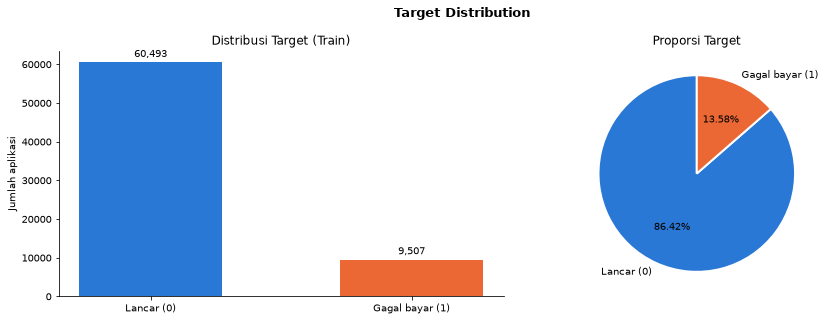

Total train : 70000
Bad rate    : 0.1358
Rasio 0:1   : 6.36x


In [ ]:
_counts = np.bincount(y)
_labels = ['Lancar (0)', 'Gagal bayar (1)']
_colors = ['#2a78d6', '#eb6834']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

_bars = ax1.bar(_labels, _counts, color=_colors, width=0.55)
ax1.bar_label(_bars, labels=[f'{c:,}' for c in _counts], padding=3)
ax1.set_ylabel('Jumlah aplikasi')
ax1.set_title('Distribusi Target (Train)')
ax1.spines[['top', 'right']].set_visible(False)

ax2.pie(_counts, labels=_labels, colors=_colors, autopct='%1.2f%%', startangle=90,
        wedgeprops=dict(edgecolor='white', linewidth=2))
ax2.set_title('Proporsi Target')

fig.suptitle('Target Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Total train : {len(y)}')
print(f'Bad rate    : {y.mean():.4f}')
print(f'Rasio 0:1   : {_counts[0] / _counts[1]:.2f}x')

> ### Insights
> Sekitar 13,6% aplikasi gagal bayar, dengan rasio kelas sekitar 6,4 banding 1. KS hanya membandingkan urutan skor kedua kelas, jadi ketidakseimbangan ini tidak perlu dikoreksi dengan *class weight* atau *oversampling*. Yang perlu dijaga adalah proporsi kelas yang sama di setiap *fold*, sehingga validasi memakai `StratifiedKFold`.

---

## Telat Bayar Berbentuk Rantai

*Hazard* telat dihitung per panjang telat beruntun sebelumnya ($k$) pada cicilan customer *train*, tanpa melihat *target*. Bila telat bayar terjadi acak dengan tarif tetap, *hazard* akan sama di setiap $k$.

In [13]:
reps = (tables['repayment_history'].join(feats.select('customer_id', 'is_train'), on='customer_id').filter(pl.col('is_train') == 1).sort('customer_id', 'loan_id', 'due_date')
        .with_columns(miss=(pl.col('max_days_past_due') > 0).cast(pl.Int8)))
reps = reps.with_columns(run_id=(pl.col('miss') == 0).cum_sum().over('loan_id'))
reps = reps.with_columns(streak=pl.col('miss').cum_sum().over('loan_id', 'run_id').cast(pl.Int32))
reps = reps.with_columns(k=pl.col('streak').shift(1).over('loan_id'))
print(reps.drop_nulls('k').with_columns(k=pl.col('k').clip(upper_bound=3)).group_by('k').agg(hazard=pl.col('miss').mean(), n=pl.len()).sort('k'))

shape: (4, 3)
┌─────┬──────────┬────────┐
│ k   ┆ hazard   ┆ n      │
│ --- ┆ ---      ┆ ---    │
│ i32 ┆ f64      ┆ u32    │
╞═════╪══════════╪════════╡
│ 0   ┆ 0.141299 ┆ 562550 │
│ 1   ┆ 0.71233  ┆ 91511  │
│ 2   ┆ 0.762602 ┆ 58383  │
│ 3   ┆ 0.847333 ┆ 130952 │
└─────┴──────────┴────────┘


> ### Insights
> Sesudah cicilan yang dibayar tepat waktu, peluang telat pada cicilan berikutnya sekitar 0,14. Sesudah satu kali telat, peluang itu melompat ke sekitar 0,71, lalu terus naik sampai 0,85 sesudah tiga kali telat beruntun. Riwayat pembayaran lebih mirip rantai keadaan daripada tarif tetap.
>
> Fitur tarif telat biasa (`rp_frac_dpd1`) merata-ratakan seluruh cicilan dan kehilangan struktur ini. Hipotesisnya, peluang mencapai 90+ yang dihitung dari matriks transisi per customer menambah informasi di atas tarif telat. Hipotesis ini diuji sebagai Eksperimen E1 di bagian 9: blok Markov menaikkan OOF dan *public* sekaligus.

---

## Level Harga Belanja

Tabel berikut menunjukkan *bad rate* per desil `pp_mean`, yaitu rata-rata z-score log harga satuan per kategori. Tabel dihitung untuk seluruh baris dan untuk customer tanpa riwayat pinjaman.

In [14]:
def decile_table(col, mask):
    x, t = fs_train[col].to_numpy()[mask], y[mask]
    ok = np.isfinite(x)
    q = np.quantile(x[ok], np.linspace(0, 1, 11))
    d = np.clip(np.searchsorted(q, x[ok], side='right') - 1, 0, 9)
    return [round(float(t[ok][d == i].mean()), 3) for i in range(10)]


all_rows = np.ones(len(y), dtype=bool)
print('semua baris  ', decile_table('pp_mean', all_rows))
print('tanpa riwayat', decile_table('pp_mean', hist == 0))
print('KS pp_mean semua', round(ks(y[np.isfinite(fs_train['pp_mean'].to_numpy())], fs_train['pp_mean'].to_numpy()[np.isfinite(fs_train['pp_mean'].to_numpy())]), 4))

semua baris   [0.019, 0.039, 0.052, 0.074, 0.087, 0.114, 0.143, 0.182, 0.247, 0.399]
tanpa riwayat [0.014, 0.023, 0.04, 0.066, 0.071, 0.092, 0.124, 0.149, 0.23, 0.362]
KS pp_mean semua 0.3689


> ### Insights
> *Bad rate* naik monoton dari sekitar 2% di desil terbawah ke sekitar 40% di desil teratas, dengan KS satu fitur 0,369. Pola yang sama muncul pada customer tanpa riwayat (1,4% ke 36,2%), kelompok yang tidak punya data *repayment* maupun rekening.
>
> Arah sinyal ini berlawanan dengan intuisi bahwa belanja mahal menandakan kemampuan bayar. Interpretasi yang konsisten dengan data adalah satu risiko laten per customer yang tercermin di beberapa kanal sekaligus. Penambahan fitur `pp_*` memberi kenaikan *public* terbesar dalam riwayat tim, yaitu +0,016.

---

## Pergeseran Train dan Test

Jarak KS dua sampel antara *train* dan *test* dihitung untuk setiap kolom numerik. Lima kolom dengan pergeseran terbesar ditampilkan.

In [15]:
num_cols = [k for k, d in feats.schema.items() if d.is_numeric() and k not in ('application_id', 'customer_id', 'target', 'is_train')]
fs_test = feats.filter(pl.col('is_train') == 0)
shift = []
for k in num_cols:
    a, b = fs_train[k].cast(pl.Float64).to_numpy(), fs_test[k].cast(pl.Float64).to_numpy()
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) and len(b):
        shift.append((round(float(ks_2samp(a, b).statistic), 4), k))
print(sorted(shift, reverse=True)[:5])

[(0.0185, 'bp_util_b'), (0.0138, 'bc_util_mean'), (0.0132, 'bp_util_a'), (0.0127, 'bh_outstanding_delta'), (0.0127, 'ac_out_in_l3')]


> ### Insights
> Pergeseran terbesar hanya 0,0185, jauh di bawah ambang yang bermakna. Pemeriksaan klasifikasi adversarial sebelumnya memberi AUC 0,501, setara tebakan acak. *Test* adalah split acak dari populasi yang sama, sehingga tidak perlu *reweighting* atau adaptasi domain, dan validasi silang acak sudah mewakili *test*.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Strategi Validasi <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Validasi harus mensimulasikan cara *test* dibentuk. Karena *test* adalah split acak customer, dan setiap customer hanya punya satu aplikasi, validasi cukup mensimulasikan pemilihan baris acak dengan proporsi kelas terjaga.

## Skema Split

`StratifiedKFold` lima *fold* diulang dengan tiga *split seed* (42, 7, 2026). Pada riset, sebagian *fold* latih (1/7) disisihkan sebagai *inner validation* untuk *early stopping*, lalu model dilatih ulang di seluruh *fold* latih dengan jumlah pohon x1,15. Jumlah pohon hasil prosedur itu dicatat di `ROUNDS`, sehingga *notebook* ini langsung melatih dengan jumlah pohon tetap. *Fold* validasi hanya dipakai untuk menilai.

```
70.000 baris train
    |
    +-- untuk setiap split seed (42, 7, 2026) dan fold k = 0..4
         |
         +-- fold latih 4/5  -> booster dengan ROUNDS[model][seed_k] pohon
         +-- fold valid 1/5  -> prediksi OOF (hanya dinilai)
    |
    OOF = rata-rata 3 seed per baris, test = rata-rata 15 booster
```

---

## Checklist Kebocoran

- [x] *Fold* validasi tidak dipakai untuk *early stopping*
- [x] Tidak ada *target encoding*
- [x] Tidak ada seleksi fitur berbasis label
- [x] Tidak ada *threshold tuning*, KS hanya memakai urutan
- [x] Bobot *blend* tidak dituning, rata-rata *rank* bobot sama
- [x] Tidak ada grup yang terbelah, satu customer satu baris
- [x] *Cutoff* `decision_datetime` diterapkan di setiap tabel

---

## Penyusunan Frame Model

Fungsi `frames` mengubah matriks Polars menjadi pandas: kolom diurutkan alfabetis, empat kolom kategorikal dijadikan `Categorical` dengan kategori dari *train*, dan nilai tak hingga diganti `NaN`. Fungsi `outer` membuat pembagian *fold* yang sama untuk keenam model.

In [16]:
ID_COLS = ["application_id", "customer_id", "decision_datetime", "target", "is_train"]


CAT_COLS = ["loan_purpose", "region", "employment_type", "housing_status"]


N_FOLDS, INNER, REFIT = 5, 7, 1.15


def outer(y, seed):
    return list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def frames(features: pl.DataFrame):
    f = features.sort("application_id")
    tr, te = f.filter(pl.col("is_train") == 1), f.filter(pl.col("is_train") == 0)
    cols = sorted(c for c in f.columns if c not in ID_COLS)
    X, Xt = tr.select(cols).to_pandas(), te.select(cols).to_pandas()
    for c in cols:
        if c in CAT_COLS or f[c].dtype == pl.String:
            cats = sorted(X[c].dropna().unique())
            X[c], Xt[c] = pd.Categorical(X[c], categories=cats), pd.Categorical(Xt[c], categories=cats)
        else:
            X[c] = X[c].astype(float).replace([np.inf, -np.inf], np.nan)
            Xt[c] = Xt[c].astype(float).replace([np.inf, -np.inf], np.nan)
    return X, Xt, tr["target"].to_numpy().astype(int), tr["application_id"], te["application_id"]

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Tiga keluarga GBDT dipakai karena masing-masing membangun pohon dengan cara berbeda: LightGBM tumbuh per daun, XGBoost per kedalaman, dan CatBoost memakai pohon simetris dengan *ordered boosting*. Versi dangkal (`_s`) menambah regularisasi dan membatasi interaksi, sehingga kesalahannya sedikit berbeda dari versi standar.

## Arsitektur Ensemble

| Model | Kedalaman / daun | *Learning rate* | Regularisasi | Subsampel kolom | Rata-rata pohon |
|---|---|---:|---|---:|---:|
| `lgb` | 31 daun | 0,02 | `min_child_samples=100`, L2 5 | 0,5 | 604 |
| `lgb_s` | 7 daun, kedalaman 3 | 0,02 | `min_child_samples=200`, L2 10 | 0,4 | 1.639 |
| `xgb` | kedalaman 5 | 0,02 | `min_child_weight=5`, L2 5 | 0,5 | 838 |
| `xgb_s` | kedalaman 3 | 0,02 | `min_child_weight=20`, L2 10 | 0,4 | 1.512 |
| `cat` | kedalaman 6 | 0,03 | L2 5 | - | 1.395 |
| `cat_s` | kedalaman 4 | 0,03 | L2 10 | - | 1.957 |

Kolom kategorikal ditangani secara bawaan oleh setiap pustaka: `Categorical` pandas untuk LightGBM dan XGBoost, serta `cat_features` berupa *string* untuk CatBoost.

---

## Konfigurasi dan `fit_one`

Parameter sama persis dengan kernel v72. `ROUNDS` menyimpan jumlah pohon untuk setiap kombinasi model, *seed*, dan *fold* dari log kernel, jadi tahap *early stopping* tidak diulang. `fit_one` melatih satu *booster* pada indeks latih dan memprediksi daftar *frame* yang diminta (*fold* validasi dan *test*).

In [17]:
THREADS = CFG.THREADS

LGB = dict(objective="binary", metric="auc", learning_rate=0.02, num_leaves=31, min_child_samples=100,
           feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, n_jobs=THREADS)


LGB_S = dict(LGB, num_leaves=7, max_depth=3, min_child_samples=200, feature_fraction=0.4, lambda_l2=10.0)


XGB = dict(objective="binary:logistic", eval_metric="auc", learning_rate=0.02, max_depth=5, min_child_weight=5,
           subsample=0.8, colsample_bytree=0.5, reg_lambda=5.0, tree_method="hist", device="cuda")


XGB_S = dict(XGB, max_depth=3, min_child_weight=20, colsample_bytree=0.4, reg_lambda=10.0)


CAT = dict(learning_rate=0.03, depth=6, l2_leaf_reg=5, loss_function="Logloss", eval_metric="AUC",
           task_type="GPU", verbose=0)


CAT_S = dict(CAT, depth=4, l2_leaf_reg=10)


XGB, XGB_S = dict(XGB, device=CFG.XGB_DEVICE), dict(XGB_S, device=CFG.XGB_DEVICE)
CAT, CAT_S = dict(CAT, **CFG.CAT_PARAMS), dict(CAT_S, **CFG.CAT_PARAMS)
ROUNDS = {'lgb': {'42_0': 688, '42_1': 436, '42_2': 739, '42_3': 804, '42_4': 710, '7_0': 566, '7_1': 439, '7_2': 502, '7_3': 646, '7_4': 456, '2026_0': 562, '2026_1': 495, '2026_2': 672, '2026_3': 515, '2026_4': 825}, 'lgb_s': {'42_0': 2403, '42_1': 1048, '42_2': 2192, '42_3': 1418, '42_4': 1780, '7_0': 1242, '7_1': 1336, '7_2': 1900, '7_3': 1935, '7_4': 1415, '2026_0': 1706, '2026_1': 1321, '2026_2': 1477, '2026_3': 1239, '2026_4': 2173}, 'xgb': {'42_0': 894, '42_1': 648, '42_2': 1044, '42_3': 956, '42_4': 835, '7_0': 715, '7_1': 874, '7_2': 1057, '7_3': 814, '7_4': 756, '2026_0': 825, '2026_1': 670, '2026_2': 766, '2026_3': 663, '2026_4': 1057}, 'xgb_s': {'42_0': 1886, '42_1': 1218, '42_2': 1546, '42_3': 1882, '42_4': 1868, '7_0': 1321, '7_1': 1417, '7_2': 1614, '7_3': 1355, '7_4': 1275, '2026_0': 1721, '2026_1': 962, '2026_2': 1771, '2026_3': 1203, '2026_4': 1647}, 'cat': {'42_0': 1891, '42_1': 1229, '42_2': 989, '42_3': 1744, '42_4': 1674, '7_0': 1106, '7_1': 1569, '7_2': 1091, '7_3': 1678, '7_4': 946, '2026_0': 1308, '2026_1': 1553, '2026_2': 902, '2026_3': 1211, '2026_4': 2028}, 'cat_s': {'42_0': 1951, '42_1': 1229, '42_2': 1801, '42_3': 2236, '42_4': 1170, '7_0': 1546, '7_1': 2146, '7_2': 2524, '7_3': 3028, '7_4': 1728, '2026_0': 1976, '2026_1': 2506, '2026_2': 2091, '2026_3': 1425, '2026_4': 1993}}


def cat_str(df):
    out = df.copy()
    for k in CAT_COLS:
        out[k] = out[k].astype(str)
    return out


def fit_one(name, X, y, tr, seed, rounds, th, frames):
    if name.startswith("lgb"):
        p = dict(LGB if name == "lgb" else LGB_S, n_jobs=th, seed=seed)
        m = lgb.train(p, lgb.Dataset(X.iloc[tr], y[tr]), rounds)
        return m, ".txt", [m.predict(r) for r in frames]
    if name.startswith("xgb"):
        p = dict(XGB if name == "xgb" else XGB_S, seed=seed)
        m = xgb.train(p, xgb.DMatrix(X.iloc[tr], y[tr], enable_categorical=True), rounds)
        return m, ".ubj", [m.predict(xgb.DMatrix(r, enable_categorical=True)) for r in frames]
    p = dict(CAT if name == "cat" else CAT_S)
    m = CatBoostClassifier(**p, iterations=rounds, random_seed=seed)
    m.fit(Pool(cat_str(X.iloc[tr]), y[tr], cat_features=[k for k in CAT_COLS if k in X.columns]))
    return m, ".cbm", [m.predict_proba(cat_str(r))[:, 1] for r in frames]

---

## Pelatihan 90 *Booster*

`train_member` melatih satu model untuk 3 *seed* x 5 *fold*. Setiap *booster* disimpan ke `CFG.MODEL_DIR`, KS *fold* validasinya dicatat, prediksi OOF dirata-ratakan antar-*seed*, dan prediksi *test* dirata-ratakan dari 15 *booster*. Peringatan CatBoost tentang AUC di GPU hanya memengaruhi frekuensi pencatatan metrik, bukan pelatihan.

In [18]:
def train_member(name):
    oof, test, log = np.zeros(len(y_tree)), np.zeros(len(Xt)), []
    for seed in CFG.SEEDS:
        for k, (tr, va) in enumerate(outer(y_tree, seed)):
            t0 = time.time()
            m, ext, (pv, pt) = fit_one(name, X, y_tree, tr, seed, ROUNDS[name][f'{seed}_{k}'], CFG.THREADS, [X.iloc[va], Xt])
            m.save_model(str(CFG.MODEL_DIR / f'{name}_s{seed}_f{k}{ext}'))
            oof[va] += pv / len(CFG.SEEDS)
            test += pt / (len(CFG.SEEDS) * N_FOLDS)
            log.append(dict(model=name, seed=seed, fold=k, ks=ks(y_tree[va], pv), budget=ROUNDS[name][f'{seed}_{k}'], sec=round(time.time() - t0, 1)))
            print(log[-1], flush=True)
            pd.DataFrame(log).to_csv(CFG.PRED_DIR / f'log_{name}.csv', index=False)
    pl.DataFrame({'application_id': ids_tree, 'target': y_tree, name: oof}).write_parquet(CFG.PRED_DIR / f'oof_{name}.parquet')
    pl.DataFrame({'application_id': test_tree, name: test}).write_parquet(CFG.PRED_DIR / f'test_{name}.parquet')


X, Xt, y_tree, ids_tree, test_tree = frames(feats)
if CFG.RUN_MODE == 'end_to_end':
    for m in CFG.SIX:
        train_member(m)
print(X.shape, Xt.shape)

{'model': 'lgb', 'seed': 42, 'fold': 0, 'ks': 0.5155923650921456, 'budget': 688, 'sec': 21.0}
{'model': 'lgb', 'seed': 42, 'fold': 1, 'ks': 0.5269706144716401, 'budget': 436, 'sec': 14.0}
{'model': 'lgb', 'seed': 42, 'fold': 2, 'ks': 0.5223034374615628, 'budget': 739, 'sec': 22.0}
{'model': 'lgb', 'seed': 42, 'fold': 3, 'ks': 0.5127057352685283, 'budget': 804, 'sec': 23.5}
{'model': 'lgb', 'seed': 42, 'fold': 4, 'ks': 0.5461173288803896, 'budget': 710, 'sec': 21.2}
{'model': 'lgb', 'seed': 7, 'fold': 0, 'ks': 0.5296569390551794, 'budget': 566, 'sec': 16.5}
{'model': 'lgb', 'seed': 7, 'fold': 1, 'ks': 0.539301159959529, 'budget': 439, 'sec': 14.2}
{'model': 'lgb', 'seed': 7, 'fold': 2, 'ks': 0.5274228714281994, 'budget': 502, 'sec': 15.7}
{'model': 'lgb', 'seed': 7, 'fold': 3, 'ks': 0.5216194454019827, 'budget': 646, 'sec': 19.4}
{'model': 'lgb', 'seed': 7, 'fold': 4, 'ks': 0.5170107459254505, 'budget': 456, 'sec': 14.7}
{'model': 'lgb', 'seed': 2026, 'fold': 0, 'ks': 0.5223241764125607

Default metric period is 5 because AUC is/are not implemented for GPU


{'model': 'cat', 'seed': 42, 'fold': 0, 'ks': 0.5193515064804439, 'budget': 1891, 'sec': 38.3}


Default metric period is 5 because AUC is/are not implemented for GPU


{'model': 'cat', 'seed': 42, 'fold': 1, 'ks': 0.5296345479445634, 'budget': 1229, 'sec': 24.8}


Default metric period is 5 because AUC is/are not implemented for GPU


... (51 outputs left out)

Default metric period is 5 because AUC is/are not implemented for GPU


{'model': 'cat_s', 'seed': 2026, 'fold': 3, 'ks': 0.5333094658605614, 'budget': 1425, 'sec': 18.3}


Default metric period is 5 because AUC is/are not implemented for GPU


{'model': 'cat_s', 'seed': 2026, 'fold': 4, 'ks': 0.5227859616149153, 'budget': 1993, 'sec': 25.2}
(70000, 242) (30000, 242)


> ### Insights
> Seluruh 90 *booster* selesai dalam sekitar 1.575 detik. CatBoost paling lama (sekitar 790 detik untuk dua konfigurasi), disusul LightGBM di CPU (sekitar 577 detik), sedangkan XGBoost di GPU hanya sekitar 208 detik. Matriks latih akhir berukuran 70.000 x 242 dan *test* 30.000 x 242.

---

## Diagnostik per *Fold*

Skor per *fold* dibaca dari log pelatihan. Rata-rata, simpangan baku, *fold* terburuk, dan *fold* terbaik menunjukkan seberapa besar *noise* evaluasi dibanding selisih antarmodel.

In [19]:
logs = pl.concat([pl.read_csv(CFG.PRED_DIR / f'log_{m}.csv') for m in CFG.SIX])
print(logs.group_by('model').agg(mean=pl.col('ks').mean().round(5), std=pl.col('ks').std().round(5), worst=pl.col('ks').min().round(5), best=pl.col('ks').max().round(5), rounds=pl.col('budget').mean().round(0)).sort('model'))

shape: (6, 6)
┌───────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ model ┆ mean    ┆ std     ┆ worst   ┆ best    ┆ rounds │
│ ---   ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---    │
│ str   ┆ f64     ┆ f64     ┆ f64     ┆ f64     ┆ f64    │
╞═══════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ cat   ┆ 0.52465 ┆ 0.00909 ┆ 0.51178 ┆ 0.54501 ┆ 1395.0 │
│ cat_s ┆ 0.52456 ┆ 0.00771 ┆ 0.51348 ┆ 0.53965 ┆ 1957.0 │
│ lgb   ┆ 0.5254  ┆ 0.00912 ┆ 0.51271 ┆ 0.54612 ┆ 604.0  │
│ lgb_s ┆ 0.52515 ┆ 0.00872 ┆ 0.51519 ┆ 0.54434 ┆ 1639.0 │
│ xgb   ┆ 0.52501 ┆ 0.00931 ┆ 0.51209 ┆ 0.54327 ┆ 838.0  │
│ xgb_s ┆ 0.52602 ┆ 0.0089  ┆ 0.51584 ┆ 0.54685 ┆ 1512.0 │
└───────┴─────────┴─────────┴─────────┴─────────┴────────┘


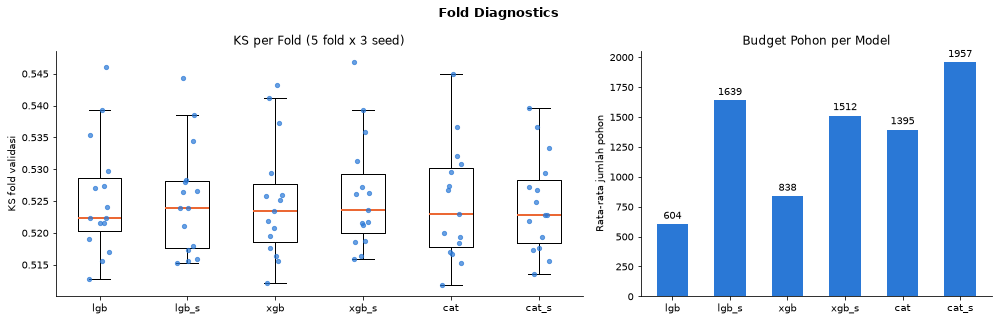

In [ ]:
_ldf = logs.to_pandas()
_data = [_ldf.loc[_ldf['model'] == m, 'ks'].to_numpy() for m in CFG.SIX]
_rounds = [_ldf.loc[_ldf['model'] == m, 'budget'].mean() for m in CFG.SIX]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [3, 2]})

ax1.boxplot(_data, widths=0.5, showfliers=False, medianprops=dict(color='#eb6834', linewidth=2))
for i, d in enumerate(_data):
    _jit = np.random.default_rng(i).uniform(-0.12, 0.12, len(d))
    ax1.scatter(np.full(len(d), i + 1) + _jit, d, s=18, color='#2a78d6', alpha=0.7, zorder=3)
ax1.set_xticks(range(1, len(CFG.SIX) + 1), CFG.SIX)
ax1.set_ylabel('KS fold validasi')
ax1.set_title('KS per Fold (5 fold x 3 seed)')
ax1.spines[['top', 'right']].set_visible(False)

_bars = ax2.bar(CFG.SIX, _rounds, color='#2a78d6', width=0.55)
ax2.bar_label(_bars, fmt='%.0f', padding=3)
ax2.set_ylabel('Rata-rata jumlah pohon')
ax2.set_title('Budget Pohon per Model')
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('Fold Diagnostics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

> ### Insights
> Rata-rata KS per *fold* keenam model berada di rentang sempit 0,5246 sampai 0,5260, sedangkan rentang antar-*fold* dalam satu model mencapai sekitar 0,03 (0,512 sampai 0,547). Selisih antarmodel jauh lebih kecil dari *noise* *fold*, sehingga kandidat tidak boleh dibandingkan dari satu *fold*. Kandidat dinilai dengan kemenangan per *fold* dan *paired bootstrap*.
>
> Model dangkal membutuhkan dua sampai tiga kali lebih banyak pohon untuk mencapai skor yang setara. Kapasitas per pohon yang lebih kecil diimbangi jumlah pohon, dengan hasil akhir yang hampir sama.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Kesalahan dan Ensemble <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini memuat prediksi OOF keenam model, mengukur di kelompok mana model lemah, lalu menggabungkan keenamnya dengan rata-rata *rank*.

## KS per Kelompok Riwayat

Prediksi OOF dan *test* dimuat dari `CFG.PRED_DIR` setelah urutan ID dan *target* diverifikasi. Setiap model lalu dinilai secara *pooled* dan terpisah untuk customer tanpa riwayat dan customer berriwayat. *Pooled* KS dapat menyembunyikan penurunan di salah satu kelompok, jadi evaluasi per kelompok diperlukan.

In [20]:
oof_m, test_m = {}, {}
for m in CFG.SIX:
    a = pl.read_parquet(CFG.PRED_DIR / f'oof_{m}.parquet')
    assert (a['application_id'] == train_ids).all() and (a['target'].to_numpy() == y).all()
    oof_m[m] = a[m].to_numpy()
    test_m[m] = sample.join(pl.read_parquet(CFG.PRED_DIR / f'test_{m}.parquet'), on='application_id', how='left', maintain_order='left')[m].to_numpy()


def group_row(s):
    return dict(KS=round(ks(y, s), 5), AUC=round(roc_auc_score(y, s), 5), KS_tanpa_riwayat=round(ks(y[hist == 0], s[hist == 0]), 5), KS_berriwayat=round(ks(y[hist == 1], s[hist == 1]), 5))


print(pl.DataFrame([dict(model=m, **group_row(oof_m[m])) for m in CFG.SIX]))

shape: (6, 5)
┌───────┬─────────┬─────────┬──────────────────┬───────────────┐
│ model ┆ KS      ┆ AUC     ┆ KS_tanpa_riwayat ┆ KS_berriwayat │
│ ---   ┆ ---     ┆ ---     ┆ ---              ┆ ---           │
│ str   ┆ f64     ┆ f64     ┆ f64              ┆ f64           │
╞═══════╪═════════╪═════════╪══════════════════╪═══════════════╡
│ lgb   ┆ 0.52496 ┆ 0.84532 ┆ 0.4999           ┆ 0.53563       │
│ lgb_s ┆ 0.52442 ┆ 0.84574 ┆ 0.4972           ┆ 0.53458       │
│ xgb   ┆ 0.52494 ┆ 0.84539 ┆ 0.49797          ┆ 0.53633       │
│ xgb_s ┆ 0.52484 ┆ 0.84578 ┆ 0.49526          ┆ 0.53646       │
│ cat   ┆ 0.52108 ┆ 0.84438 ┆ 0.48869          ┆ 0.53276       │
│ cat_s ┆ 0.5219  ┆ 0.84422 ┆ 0.49058          ┆ 0.53533       │
└───────┴─────────┴─────────┴──────────────────┴───────────────┘


> ### Insights
> Semua model lebih lemah pada customer tanpa riwayat (KS 0,489 sampai 0,500) dibanding customer berriwayat (0,533 sampai 0,536). Kelompok tanpa riwayat hanya punya data aplikasi, biro, dan *e-commerce*, sehingga sinyalnya lebih sedikit. Selisih ini memotivasi eksperimen model per segmen di bagian 9.
>
> Di antara keenam model, CatBoost paling lemah pada kelompok tanpa riwayat, sedangkan LightGBM dan XGBoost standar paling kuat. Selisihnya kecil, dan rata-rata *rank* menutupi kelemahan setiap model.

---

## Korelasi Antarmodel

Korelasi *rank* antarmodel menunjukkan seberapa banyak *noise* yang dapat dihilangkan oleh rata-rata. Korelasi mendekati 1 berarti model membuat kesalahan yang hampir sama.

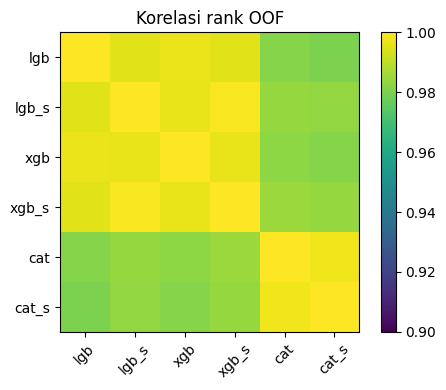

korelasi terendah 0.9804


In [21]:
rank_o = np.column_stack([rankdata(oof_m[m]) for m in CFG.SIX])
corr = np.corrcoef(rank_o, rowvar=False)
plt.figure(figsize=(5, 4))
plt.imshow(corr, vmin=0.9, vmax=1)
plt.xticks(range(6), CFG.SIX, rotation=45)
plt.yticks(range(6), CFG.SIX)
plt.colorbar()
plt.title('Korelasi rank OOF')
plt.tight_layout()
plt.show()
print('korelasi terendah', round(float(corr.min()), 4))

> ### Insights
> Korelasi *rank* terendah adalah 0,9804, jadi keenam model sangat mirip. Manfaat *blend* karena itu kecil tetapi stabil, dan berasal dari perataan *noise* *seed* serta perbedaan cara membangun pohon. Pasangan dengan keluarga sama (misalnya `lgb` dan `lgb_s`) lebih berkorelasi daripada pasangan lintas keluarga.

---

## Rank Blend

**Pemilihan kandidat.** Enam model dipilih sejak v22, sebelum blok Markov ada, sehingga bukan hasil seleksi pada OOF akhir.

**Blend.** Rata-rata *rank* bobot sama. Pencarian bobot dan *blend* logit tidak mengalahkan rata-rata *rank* pada eksperimen 275, jadi tidak ada parameter yang dituning.

**Stacking.** Tidak dipakai. *Stacking* tahap dua di atas OOF memberi sekitar +0,0007 per *fold* bahkan untuk blok kontrol yang tidak berguna, sehingga gain-nya merupakan artefak.

In [22]:
oof_rank = np.mean([rankdata(oof_m[m]) for m in CFG.SIX], 0) / len(y)
print(group_row(oof_rank))

{'KS': 0.52558, 'AUC': np.float64(0.84611), 'KS_tanpa_riwayat': 0.49665, 'KS_berriwayat': 0.53679}


Kurva KS di bawah menampilkan distribusi kumulatif skor *blend* untuk kedua kelas. Jarak vertikal terbesar antara kedua kurva adalah nilai KS, dan posisinya menunjukkan titik potong yang menentukan skor.

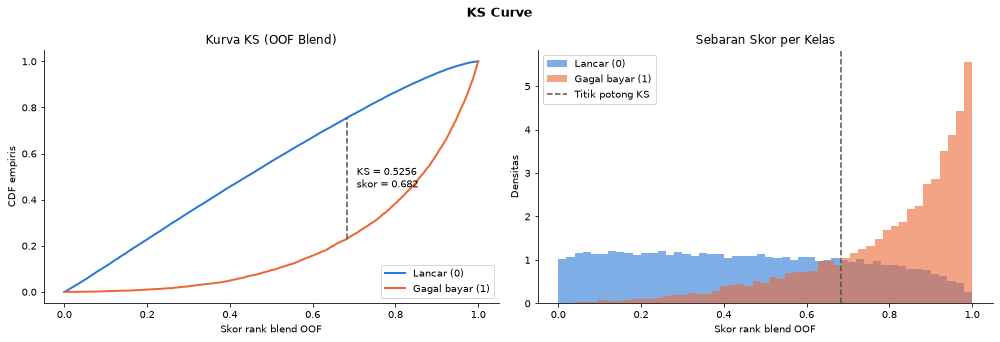

KS pada titik potong     : 0.52558 (ks_2samp 0.52558)
Porsi di atas titik potong: 0.3168
Recall gagal bayar        : 0.7710
Porsi lancar tertolak     : 0.2454


In [ ]:
_grid = np.unique(oof_rank)
_F1 = np.searchsorted(np.sort(oof_rank[y == 1]), _grid, side='right') / (y == 1).sum()
_F0 = np.searchsorted(np.sort(oof_rank[y == 0]), _grid, side='right') / (y == 0).sum()
_i = int(np.argmax(_F0 - _F1))
_cut = _grid[_i]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

ax1.plot(_grid, _F0, color='#2a78d6', lw=2, label='Lancar (0)')
ax1.plot(_grid, _F1, color='#eb6834', lw=2, label='Gagal bayar (1)')
ax1.vlines(_cut, _F1[_i], _F0[_i], color='#52514e', ls='--', lw=1.5)
ax1.annotate(f'KS = {_F0[_i] - _F1[_i]:.4f}\nskor = {_cut:.3f}', (_cut, (_F0[_i] + _F1[_i]) / 2),
             xytext=(10, 0), textcoords='offset points', va='center')
ax1.set_xlabel('Skor rank blend OOF')
ax1.set_ylabel('CDF empiris')
ax1.set_title('Kurva KS (OOF Blend)')
ax1.legend(loc='lower right')
ax1.spines[['top', 'right']].set_visible(False)

ax2.hist(oof_rank[y == 0], bins=50, density=True, alpha=0.6, color='#2a78d6', label='Lancar (0)')
ax2.hist(oof_rank[y == 1], bins=50, density=True, alpha=0.6, color='#eb6834', label='Gagal bayar (1)')
ax2.axvline(_cut, color='#52514e', ls='--', lw=1.5, label='Titik potong KS')
ax2.set_xlabel('Skor rank blend OOF')
ax2.set_ylabel('Densitas')
ax2.set_title('Sebaran Skor per Kelas')
ax2.legend()
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('KS Curve', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'KS pada titik potong     : {_F0[_i] - _F1[_i]:.5f} (ks_2samp {ks(y, oof_rank):.5f})')
print(f'Porsi di atas titik potong: {(oof_rank > _cut).mean():.4f}')
print(f'Recall gagal bayar        : {1 - _F1[_i]:.4f}')
print(f'Porsi lancar tertolak     : {1 - _F0[_i]:.4f}')

> ### Insights
> Rata-rata *rank* memberi KS *pooled* 0,52558 dan AUC 0,84611, sedikit di atas model tunggal terbaik (`lgb`, KS 0,52496 dan AUC 0,84532). Kenaikannya kecil karena keenam model sangat berkorelasi, tetapi *blend* tidak lebih buruk dari anggota mana pun dan menghilangkan risiko memilih satu model yang kebetulan unggul.
>
> Kurva KS mencapai jarak terbesar di skor 0,682: 77,1% aplikasi gagal bayar berada di atas titik potong, sedangkan hanya 24,5% aplikasi lancar ikut tertolak. Sekitar 32% aplikasi berada di atas titik ini. Kesalahan yang mahal adalah salah urut di sekitar titik potong tersebut, bukan di ekor distribusi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Riwayat Eksperimen dan Pemilihan Model <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini merangkum 39 submisi dan eksperimen lokal yang membentuk resep final. Fakta, hipotesis, dan keputusan dipisahkan, dan hasil negatif tetap dicatat agar alasan setiap keputusan dapat ditelusuri. Angka OOF hanya dicantumkan bila dihitung dengan skema validasi yang sebanding.

## Baseline

Skor konstan memberi KS 0. Tabel berikut menunjukkan perjalanan dari model awal ke basis enam GBDT.

| Baseline | *Public* |
|---|---:|
| LightGBM awal | 0,50227 |
| XGBoost awal | 0,50053 |
| CatBoost awal | 0,50662 |
| Regresi logistik *rank-gauss* (v39c) | 0,55835 |
| Enam GBDT bersih (v39a) | 0,56337 |

Regresi logistik dengan fitur yang sama sudah mencapai 0,55835. Artinya sebagian besar sinyal berasal dari fitur, bukan dari kapasitas model. Lompatan dari 0,50 ke 0,56 datang dari fitur perilaku dan level harga.

---

## Dekomposisi Masalah

**Motivasi.** 30.000 aplikasi tidak punya riwayat pinjaman, sehingga tidak punya blok *repayment*, rekening, dan aplikasi lama. KS kelompok ini juga lebih rendah (bagian 8).

**Hipotesis.** Model terpisah per `has_history` lebih tepat daripada satu model global.

**Cara validasi.** *Fold* identik, lalu bandingkan OOF dan *public*.

**Bukti.** OOF naik (`eight_seg` 0,52706, `xgb_seg16` 0,52783), tetapi *public* turun (0,56533 dan 0,56225, dibanding v72 0,56822).

**Keputusan.** **REJECT.** Model global dipertahankan.

---

## Famili Eksperimen

| Famili | Tujuan | Kandidat | *Public* terbaik | Keputusan |
|---|---|---|---:|---|
| A *Global structured* | Sinyal tabular utama | LightGBM, XGBoost, CatBoost | 0,56337 | KEEP |
| B *Repayment dynamics* | Dinamika telat | Rantai Markov di atas famili A | 0,56822 | KEEP |
| C *Segment* | Pisahkan customer tanpa riwayat | Pohon per `has_history` | 0,56533 | REJECT |
| D *Smooth* | Bias induktif berbeda | MLP, RealMLP, FM, *varying coefficient* | 0,56374 | REJECT |
| E *Foundation model* | Representasi *pretrained* | Kumo, Causilo, TabPFN | 0,56470 | REJECT |

---

## Eksperimen E1: Apakah Rantai Markov Menambah Informasi?

**Pertanyaan.** Apakah peluang mencapai 90+ per customer menaikkan skor di atas enam GBDT?

**Hipotesis.** *Hazard* yang melompat sesudah telat pertama (bagian 5) tidak tertangkap penuh oleh tarif telat.

```
Baseline : 6 GBDT pada 232 kolom
Perubahan: + 10 kolom Markov (f251)
Validasi : StratifiedKFold 5 fold, inner 1/7, refit x1,15, seed 42, 7, 2026
```

| Metrik | Baseline | Eksperimen | Delta |
|---|---:|---:|---:|
| OOF KS | 0,52448 | 0,52580 | +0,00132 |
| *Public* | 0,56337 | 0,56822 | +0,00485 |

**Keputusan.** **KEEP.** Ini satu-satunya perubahan terakhir yang naik di OOF dan *public* sekaligus.

---

## Eksperimen E2: Apakah Pohon per Segmen dan Model Halus Lebih Baik?

**Pertanyaan.** Apakah bias induktif yang berbeda menaikkan skor?

```
Baseline : v72
Perubahan: + pohon per has_history
           + varying coefficient, FM, MLP, RealMLP (N7)
```

| Metrik | v72 | N7 | Delta |
|---|---:|---:|---:|
| OOF KS | 0,52580 | 0,53047 | +0,00467 |
| *Public* | 0,56822 | 0,55882 | -0,00940 |

**Keputusan.** **REJECT.** Selisih *public* sekitar 3,4 simpangan baku dari simulasi 9.000 baris berpasangan. Gain OOF tidak berpindah ke *public*.

---

## Registri Eksperimen

| ID | Famili | Ide utama | OOF | *Public* | Status |
|---|---|---|---:|---:|---|
| v39a | *global* | Enam GBDT bersih | 0,52448 | 0,56337 | KEEP sebagai basis |
| v31 | *foundation* | GBDT + Causilo + Kumo | 0,52613 | 0,56405 | REJECT |
| v70 | *foundation* | Kumo + *spline* + *offset* bulan | beda skema | 0,56470 | REJECT |
| v71 | *dynamics* | Enam GBDT + Markov, 2 *seed* | tidak dicatat | 0,56649 | digantikan v72 |
| v71c | *postprocessing* | v71 + *offset* logit per bulan | tidak dicatat | 0,56442 | REJECT |
| **v72** | ***dynamics*** | **Enam GBDT + Markov, 3 *seed*** | **0,52580** | **0,56822** | **FINAL** |
| v73 | *dynamics* | v72 dengan 8 *seed* | 0,52577 | 0,56719 | REJECT |
| v74 `eight_seg` | *segment* | Delapan pohon + segmen | 0,52706 | 0,56533 | REJECT |
| v74 `xgb_seg16` | *segment* | XGBoost per segmen, 16 *seed* | 0,52783 | 0,56225 | REJECT |
| v75 C | *smooth* | Pohon segmen + MLP | 0,52861 | 0,56374 | REJECT |
| v76 N7 | *smooth* | Pohon segmen + VC + FM + NN | 0,53047 | 0,55882 | REJECT |

---

## Postprocessing

Tidak ada *postprocessing* pada berkas final. Satu-satunya percobaan, *offset* logit per bulan keputusan, menurunkan *public*:

```
Sebelum : v71 public 0,56649
Sesudah : v71c, offset logit per bulan, public 0,56442
Delta   : -0,00207
Putusan : REJECT
```

KS hanya memakai urutan, jadi kalibrasi global tidak mengubah skor. Koreksi per kelompok hanya berguna bila kelompok itu salah diurutkan relatif terhadap kelompok lain, dan data tidak menunjukkan pola tersebut.

---

## Hasil Negatif

| Eksperimen | Harapan | Hasil | Alasan ditolak |
|---|---|---|---|
| Pohon per segmen | Customer tanpa riwayat lebih tepat | OOF +0,002, *public* -0,003 sampai -0,006 | Tidak berpindah ke *public* |
| Pohon segmen + VC + FM + NN (N7) | Bias induktif berbeda | OOF +0,0047, *public* -0,0094 | Tidak berpindah ke *public* |
| *Foundation model* tunggal | Representasi lebih kaya | *Public* 0,5533 sampai 0,5647 | Di bawah pohon |
| *Stacking* tahap dua | Koreksi residual | Gain sama pada blok kontrol | Artefak *stacking* |
| *Down-weighting* label mencurigakan | Label lebih bersih | -0,002 sampai -0,0035 | Membuang sinyal |
| *Pseudo-label* | Data tambahan | Sekitar 0 pada 70 ribu label | Tidak diperlukan |
| *Tuning* LightGBM dan XGBoost | Konfigurasi lebih baik | Tidak ada yang melampaui v22 | Sudah jenuh |
| *Offset* logit per bulan | Koreksi waktu | *Public* -0,002 | *Noise* |
| 150 ide dari literatur | Sinyal baru | Satu famili lolos uji ganda, gain sekitar +0,001 | Gagal kontrol acak |
| 14 famili lintas tabel, 300 kolom | Sinyal residual | Tidak ada yang menang 4 dari 5 *fold* | *Null* |
| Filter *state-space*, peluruhan waktu | Estimasi lebih bersih | Gain sama dengan kontrol acak | Gagal kontrol |

---

## Audit Hasil Mencurigakan

*Public* v72 (0,56822) berada sekitar 0,042 di atas OOF (0,52580). Selisih sebesar ini harus dicurigai sebelum dipercaya.

- [x] *Preprocessing* tidak melihat *fold* validasi dan tidak ada transformasi berbasis label
- [x] *Early stopping* tidak memakai *fold* validasi
- [x] Tidak ada seleksi fitur berbasis label
- [x] Tidak ada *target encoding*
- [x] Tidak ada duplikat atau grup yang terbelah
- [x] ID tidak dipakai sebagai fitur
- [x] Tidak ada *threshold* yang dipilih
- [x] Bobot *ensemble* tidak dioptimasi
- [x] Model tidak melihat label *test*

> ### Insights
> **Mengapa skor ini mungkin nyata.** Selisih *public* terhadap OOF muncul pada semua famili model, jadi bukan ciri khusus v72. *Pipeline* tidak memakai label *test* di tahap mana pun.
>
> **Mengapa skor ini mungkin optimis.** *Public* hanya 9.000 baris dengan simpangan baku sekitar 0,011. Bias maksimum KS pada sampel kecil menyumbang sekitar +0,003, dan sisanya belum terjelaskan. *Private* bisa lebih dekat ke OOF.
>
> **Eksperimen verifikasi.** *Paired bootstrap* 9.000 baris dari OOF menunjukkan file yang sangat dekat seperti v72 dan v73 bergeser sekitar 0,001, sehingga urutan keduanya di *public* sebagian adalah undian.

---

## Pemilihan Model Final

Rubrik memberi bobot 45% ke *public*, dan *public* berkas terpilih sudah diketahui. Karena itu setiap kandidat dinilai dengan 0,45 x selisih *public* + 0,45 x taksiran selisih *private*. Taksiran *private* menggabungkan OOF yang disusutkan 0,7 dengan selisih *public*, dibobot menurut *noise* masing-masing.

| Kandidat | *Public* | OOF | Skor rubrik vs v72 | Stabilitas | Risiko kebocoran | Kompleksitas | Final |
|---|---:|---:|---:|---|---|---|---|
| **v72** | **0,56822** | 0,52580 | 0 | tinggi | rendah | rendah | **YA** |
| v70 goal054 | 0,56470 | beda skema | -0,0007 | sedang | rendah | tinggi | tidak |
| v73 | 0,56719 | 0,52577 | -0,0009 | tinggi | rendah | rendah | tidak |
| v74 `eight_seg` | 0,56533 | 0,52706 | -0,0013 | sedang | rendah | sedang | tidak |
| v75 C | 0,56374 | 0,52861 | -0,0016 | sedang | rendah | sedang | tidak |
| v76 N7 | 0,55882 | 0,53047 | -0,0035 | rendah | rendah | tinggi | tidak |

v72 tetap teratas pada sembilan kombinasi faktor penyusutan dan ketidakpastian *prior*. **Keputusan: v72.**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Sel-sel berikut memuat ulang 90 *booster* dari disk, memprediksi *test*, memverifikasi hasilnya, lalu menulis berkas submisi. Bagian ini berjalan sama pada mode `end_to_end` maupun `inference`.

## Kontrak Artefak

Artefak final mengikuti kontrak seragam, sehingga mode `inference` tidak perlu melatih ulang. Pada mode `end_to_end`, struktur yang sama ditulis ke `v72_final/run/`.

```
v72_bundle/
|-- manifest.json          SHA256 semua berkas, versi, dan metadata
|-- models/                90 booster: <model>_s<seed>_f<fold>.{txt,ubj,cbm}
|-- kernel/                oof_, test_, log_ per model dari kernel Kaggle v72
|-- refit/                 oof_, test_, log_ per model dari run end_to_end
|-- submission_final.csv   output run end_to_end
`-- submission_v72.csv     output kernel v72, sebagai pembanding
```

---

## Muat *Booster* dan Inferensi

Setiap *booster* dimuat dari `CFG.MODEL_DIR` dan memprediksi baris *test* di CPU. XGBoost dipaksa ke `device='cpu'` agar inferensi tidak bergantung pada GPU. Prediksi per model adalah rata-rata probabilitas 15 *booster*, sama seperti saat pelatihan.

In [23]:
assert set(test_tree.to_list()) == set(sample['application_id'].to_list())


def load_predict(name, seed, fold):
    path = CFG.MODEL_DIR / f'{name}_s{seed}_f{fold}'
    if name.startswith('lgb'):
        return lgb.Booster(model_file=str(path) + '.txt').predict(Xt)
    if name.startswith('xgb'):
        b = xgb.Booster()
        b.load_model(str(path) + '.ubj')
        b.set_param({'device': 'cpu'})
        return b.predict(xgb.DMatrix(Xt, enable_categorical=True))
    return CatBoostClassifier().load_model(str(path) + '.cbm').predict_proba(cat_str(Xt))[:, 1]


t0 = time.time()
infer = {}
for m in CFG.SIX:
    infer[m] = np.mean([load_predict(m, s, k) for s in CFG.SEEDS for k in range(CFG.N_FOLDS)], 0)
    print(m, 'selesai', round(time.time() - t0), 'detik', flush=True)
infer_df = pl.DataFrame({'application_id': test_tree, **infer})
infer_df = sample.join(infer_df, on='application_id', how='left', maintain_order='left')

lgb selesai 12 detik
lgb_s selesai 29 detik
xgb selesai 36 detik
xgb_s selesai 42 detik
cat selesai 44 detik
cat_s selesai 47 detik


---

## Verifikasi *Booster*

Pemeriksaan pertama memastikan *booster* termuat dengan benar: prediksi hasil muat ulang harus sama dengan prediksi yang disimpan saat pelatihan. Pemeriksaan kedua membandingkan *blend* hasil inferensi dengan *blend* dari prediksi yang disimpan. Pada mode `end_to_end`, `PRED_DIR` dan `REFIT_DIR` menunjuk ke folder `run/` yang sama.

In [24]:
rows = []
for m in CFG.SIX:
    saved = sample.join(pl.read_parquet(CFG.REFIT_DIR / f'test_{m}.parquet'), on='application_id', how='left', maintain_order='left')[m].to_numpy()
    a = pl.read_parquet(CFG.REFIT_DIR / f'oof_{m}.parquet')
    rows.append(dict(model=m, selisih_maks_saat_simpan=float(np.abs(infer_df[m].to_numpy() - saved).max()), spearman_kernel=round(float(spearmanr(infer_df[m].to_numpy(), test_m[m])[0]), 5), KS_kernel=round(ks(y, oof_m[m]), 5), KS_refit=round(ks(y, a[m].to_numpy()), 5)))
print(pl.DataFrame(rows))
infer_rank = np.mean([rankdata(infer_df[m].to_numpy()) / 30000 for m in CFG.SIX], 0)
kernel_rank = np.mean([rankdata(test_m[m]) / 30000 for m in CFG.SIX], 0)
print('Spearman blend booster lawan kernel', round(float(spearmanr(infer_rank, kernel_rank)[0]), 5))
refit_o = np.mean([rankdata(pl.read_parquet(CFG.REFIT_DIR / f'oof_{m}.parquet')[m].to_numpy()) for m in CFG.SIX], 0) / len(y)
print('OOF blend kernel', group_row(oof_rank))
print('OOF blend refit ', group_row(refit_o))

shape: (6, 5)
┌───────┬──────────────────────────┬─────────────────┬───────────┬──────────┐
│ model ┆ selisih_maks_saat_simpan ┆ spearman_kernel ┆ KS_kernel ┆ KS_refit │
│ ---   ┆ ---                      ┆ ---             ┆ ---       ┆ ---      │
│ str   ┆ f64                      ┆ f64             ┆ f64       ┆ f64      │
╞═══════╪══════════════════════════╪═════════════════╪═══════════╪══════════╡
│ lgb   ┆ 3.3307e-16               ┆ 1.0             ┆ 0.52496   ┆ 0.52496  │
│ lgb_s ┆ 3.3307e-16               ┆ 1.0             ┆ 0.52442   ┆ 0.52442  │
│ xgb   ┆ 3.3900e-7                ┆ 1.0             ┆ 0.52494   ┆ 0.52494  │
│ xgb_s ┆ 5.1782e-7                ┆ 1.0             ┆ 0.52484   ┆ 0.52484  │
│ cat   ┆ 4.4409e-16               ┆ 1.0             ┆ 0.52108   ┆ 0.52108  │
│ cat_s ┆ 4.4409e-16               ┆ 1.0             ┆ 0.5219    ┆ 0.5219   │
└───────┴──────────────────────────┴─────────────────┴───────────┴──────────┘
Spearman blend booster lawan kernel 1.0
OOF blend 

> ### Insights
> `selisih_maks_saat_simpan` sekitar 1e-16 untuk LightGBM dan CatBoost, artinya *booster* termuat identik. XGBoost berselisih sekitar 5e-7 karena dilatih dan memprediksi di GPU, sedangkan inferensi ulang berjalan di CPU. Selisih ini tidak mengubah urutan secara berarti: korelasi Spearman setiap model dan *blend* sama dengan 1,0.
>
> OOF *blend* dari kedua sumber sama persis (KS 0,52558), sehingga *output* inferensi *booster* dipakai sebagai `submission.csv`.

---

## Laporan Validasi Final

Laporan ini dihitung dari OOF *blend* pada 70.000 baris: KS *pooled*, KS per *fold* untuk 15 *fold*, KS per kuartal bulan keputusan, dan KS per kelompok riwayat.

In [25]:
per_fold = [ks(y[va], oof_rank[va]) for sd in CFG.SEEDS for _, va in outer(y, sd)]
print(f'pooled OOF KS {ks(y, oof_rank):.5f}, AUC {roc_auc_score(y, oof_rank):.5f}')
print(f'per fold: mean {np.mean(per_fold):.5f}, std {np.std(per_fold):.5f}, worst {np.min(per_fold):.5f}, best {np.max(per_fold):.5f}')
month = fs_train['dec_month'].to_numpy()
q = (month - 1) // 3 + 1
print({f'Q{k}': round(ks(y[q == k], oof_rank[q == k]), 5) for k in (1, 2, 3, 4)})
print('tanpa riwayat', round(ks(y[hist == 0], oof_rank[hist == 0]), 5), 'berriwayat', round(ks(y[hist == 1], oof_rank[hist == 1]), 5))

pooled OOF KS 0.52558, AUC 0.84611
per fold: mean 0.52800, std 0.00827, worst 0.51642, best 0.54648
{'Q1': 0.51401, 'Q2': 0.54161, 'Q3': 0.52595, 'Q4': 0.52751}
tanpa riwayat 0.49665 berriwayat 0.53679


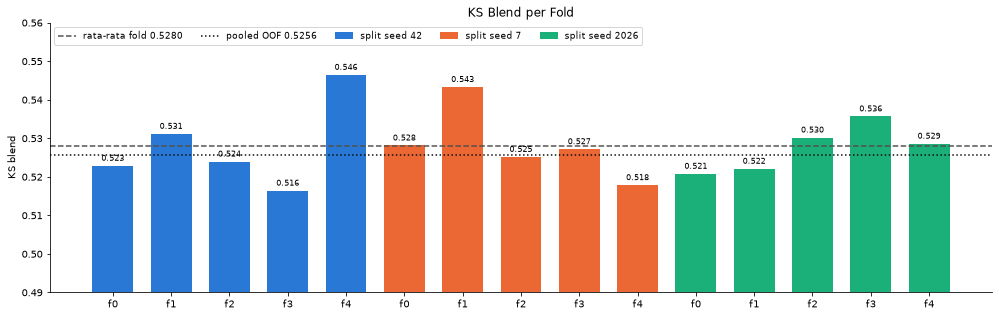

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
_seed_colors = ['#2a78d6', '#eb6834', '#1baf7a']
for j, sd in enumerate(CFG.SEEDS):
    _x = np.arange(j * CFG.N_FOLDS, (j + 1) * CFG.N_FOLDS)
    _bars = ax.bar(_x, per_fold[j * CFG.N_FOLDS:(j + 1) * CFG.N_FOLDS], color=_seed_colors[j], width=0.7,
                   label=f'split seed {sd}')
    ax.bar_label(_bars, fmt='%.3f', padding=3, fontsize=8)
ax.axhline(np.mean(per_fold), color='#52514e', ls='--', lw=1.5, label=f'rata-rata fold {np.mean(per_fold):.4f}')
ax.axhline(ks(y, oof_rank), color='#0b0b0b', ls=':', lw=1.5, label=f'pooled OOF {ks(y, oof_rank):.4f}')
ax.set_xticks(range(len(per_fold)), [f'f{k}' for _ in CFG.SEEDS for k in range(CFG.N_FOLDS)])
ax.set_ylim(0.49, 0.56)
ax.set_ylabel('KS blend')
ax.set_title('KS Blend per Fold')
ax.legend(loc='upper left', ncol=5, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

> ### Insights
> KS *pooled* *blend* adalah 0,52558 dengan AUC 0,84611. Per *fold*, rata-ratanya 0,52800 dengan simpangan baku 0,00827, dari 0,51642 sampai 0,54648. Rata-rata per *fold* sedikit di atas KS *pooled* karena KS adalah statistik maksimum: pada sampel lebih kecil, nilainya cenderung bias ke atas.
>
> Kuartal pertama (Q1) adalah kuartal terlemah dengan KS 0,514, sedangkan Q2 tertinggi dengan 0,542. Selisih kelompok riwayat tetap sekitar 0,04 (0,497 tanpa riwayat lawan 0,537 berriwayat).

### Keterbatasan yang Diketahui

- XGBoost dan CatBoost dilatih di GPU, sehingga pelatihan ulang di perangkat lain dapat memberi prediksi yang berbeda tipis.
- OOF mengandung efek seleksi dari riwayat eksperimen, walaupun resep enam model sudah dikunci lebih dulu.
- Selisih *public* di bawah 0,002 tidak dapat dibedakan pada 9.000 baris.

---

## Pembuatan Berkas Submisi

`submission.csv` adalah *output* langsung dari *booster* yang dimuat ulang, dengan rumus kernel v72: *rank* tiap model dibagi 30.000, lalu dirata-ratakan. `submission_kernel_v72.csv` memakai rumus yang sama pada prediksi *test* yang disimpan saat pelatihan. Berkas dibaca ulang dan divalidasi sebelum dianggap selesai.

In [26]:
final_test_pred = infer_rank
submission = sample.with_columns(default_probability=pl.Series(final_test_pred))
submission.write_csv(CFG.OUTPUT_DIR / 'submission.csv')
sample.with_columns(default_probability=pl.Series(kernel_rank)).write_csv(CFG.OUTPUT_DIR / 'submission_kernel_v72.csv')

reread = pl.read_csv(CFG.OUTPUT_DIR / 'submission.csv')
assert reread.height == 30000 and reread['application_id'].n_unique() == 30000
assert (reread['application_id'] == sample['application_id']).all()
assert reread['default_probability'].null_count() == 0
assert reread['default_probability'].min() >= 0 and reread['default_probability'].max() <= 1
print('sha256 submission.csv   ', file_sha(CFG.OUTPUT_DIR / 'submission.csv')[:16])
if CFG.RUN_MODE == 'inference':
    collected = pl.read_csv(CFG.ARTIFACT_DIR / 'submission_final.csv')
    gap = float(np.abs(reread['default_probability'].to_numpy() - collected['default_probability'].to_numpy()).max())
    assert gap < 5e-3
    print('sha256 run end_to_end    ', file_sha(CFG.ARTIFACT_DIR / 'submission_final.csv')[:16])
    print('identik' if gap == 0 else f'selisih maksimum {gap}')
print('Spearman lawan output kernel v72', round(float(spearmanr(infer_rank, kernel_rank)[0]), 5))

sha256 submission.csv    4be2bddbc74de13a
Spearman lawan output kernel v72 1.0


Pemeriksaan:

- [x] Jumlah baris sama dengan *test* (30.000)
- [x] Urutan ID sama dengan `sample_submission.csv`
- [x] Tidak ada NaN
- [x] Semua nilai di rentang [0, 1]
- [x] Berkas terbaca ulang
- [x] Dibandingkan dengan *blend* dari prediksi yang disimpan

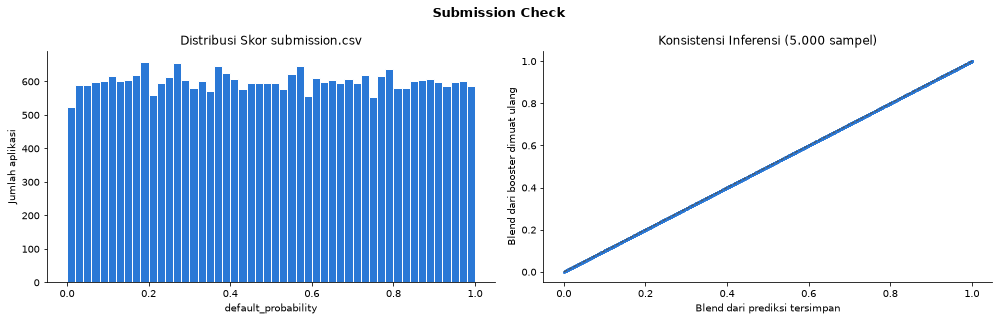

Rentang skor     : 0.00004 - 0.99998
Selisih maksimum : 8.33e-06


In [ ]:
_idx = np.random.default_rng(42).choice(len(final_test_pred), 5000, replace=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.hist(final_test_pred, bins=50, color='#2a78d6', edgecolor='white')
ax1.set_xlabel('default_probability')
ax1.set_ylabel('Jumlah aplikasi')
ax1.set_title('Distribusi Skor submission.csv')
ax1.spines[['top', 'right']].set_visible(False)

ax2.scatter(kernel_rank[_idx], final_test_pred[_idx], s=4, alpha=0.4, color='#2a78d6')
ax2.plot([0, 1], [0, 1], ls='--', color='#52514e', lw=1)
ax2.set_xlabel('Blend dari prediksi tersimpan')
ax2.set_ylabel('Blend dari booster dimuat ulang')
ax2.set_title('Konsistensi Inferensi (5.000 sampel)')
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('Submission Check', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Rentang skor     : {final_test_pred.min():.5f} - {final_test_pred.max():.5f}')
print(f'Selisih maksimum : {np.abs(final_test_pred - kernel_rank).max():.2e}')

> ### Insights
> Skor submisi tersebar hampir seragam di [0, 1] karena merupakan rata-rata *rank*. Bentuk ini wajar untuk KS, yang hanya membaca urutan. Titik-titik pada diagram sebar berada tepat di garis diagonal: selisih terbesar sekitar 8e-6 berasal dari perbedaan GPU dan CPU pada XGBoost dan tidak mengubah urutan secara berarti.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="11"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kontribusi Fitur

*Gain importance* LightGBM dirata-ratakan dari 15 *booster* `lgb`, lalu dikelompokkan per famili fitur. Analisis ini memperlihatkan blok informasi mana yang paling banyak dipakai model untuk memisahkan kelas. *Gain* mengukur kontribusi dalam pelatihan, bukan dampak kausal, sehingga fitur yang berkorelasi dapat saling berbagi *gain*.

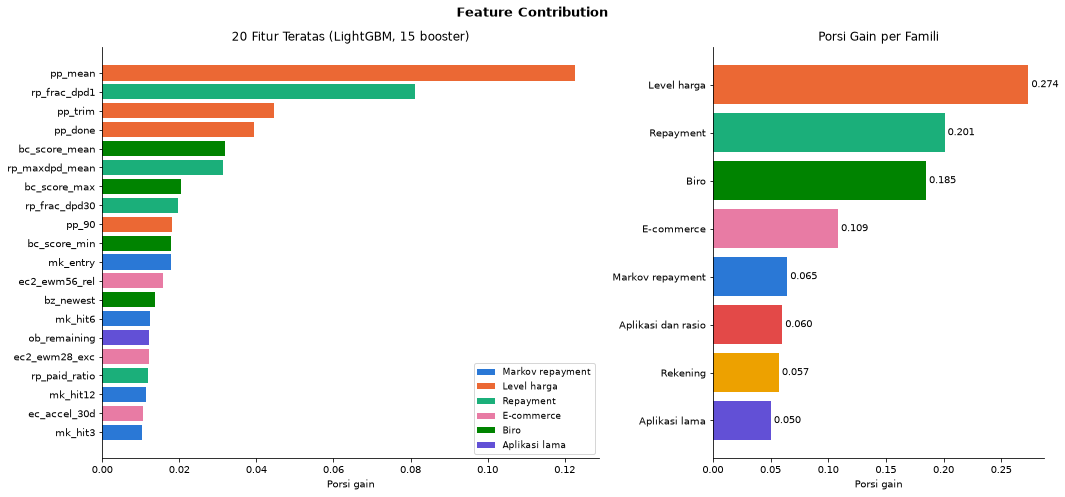

                     famili  porsi_gain
pp_mean         Level harga      0.1228
rp_frac_dpd1      Repayment      0.0813
pp_trim         Level harga      0.0445
pp_done         Level harga      0.0394
bc_score_mean          Biro      0.0319
rp_maxdpd_mean    Repayment      0.0312
bc_score_max           Biro      0.0205
rp_frac_dpd30     Repayment      0.0196
pp_90           Level harga      0.0180
bc_score_min           Biro      0.0179


In [ ]:
_FAMILY = [('mk_', 'Markov repayment'), ('pp_', 'Level harga'), ('rp_', 'Repayment'), ('rq_', 'Repayment'),
           ('sv_', 'Repayment'), ('ac_', 'Rekening'), ('cf_', 'Rekening'), ('ec_', 'E-commerce'),
           ('ec2_', 'E-commerce'), ('bc_', 'Biro'), ('bh_', 'Biro'), ('bp_', 'Biro'), ('bz_', 'Biro'),
           ('pv_', 'Aplikasi lama'), ('ob_', 'Aplikasi lama')]
_FAM_COLORS = {'Markov repayment': '#2a78d6', 'Level harga': '#eb6834', 'Repayment': '#1baf7a',
               'Rekening': '#eda100', 'E-commerce': '#e87ba4', 'Biro': '#008300',
               'Aplikasi lama': '#6250d6', 'Aplikasi dan rasio': '#e34948'}

_imp = {}
for sd in CFG.SEEDS:
    for k in range(CFG.N_FOLDS):
        _b = lgb.Booster(model_file=str(CFG.MODEL_DIR / f'lgb_s{sd}_f{k}.txt'))
        for _f, _g in zip(_b.feature_name(), _b.feature_importance('gain')):
            _imp[_f] = _imp.get(_f, 0.0) + _g / (len(CFG.SEEDS) * CFG.N_FOLDS)
_imp = pd.Series(_imp).sort_values(ascending=False)
_share = _imp / _imp.sum()
_fam = pd.Series({c: next((n for p, n in _FAMILY if c.startswith(p)), 'Aplikasi dan rasio') for c in _imp.index})
_fam_share = _share.groupby(_fam).sum().sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [3, 2]})

_top = _share.head(20)[::-1]
_pos = np.arange(len(_top))
for n, c in _FAM_COLORS.items():
    _m = (_fam[_top.index] == n).to_numpy()
    if _m.any():
        ax1.barh(_pos[_m], _top.values[_m], color=c, label=n)
ax1.set_yticks(_pos, _top.index)
ax1.set_xlabel('Porsi gain')
ax1.set_title('20 Fitur Teratas (LightGBM, 15 booster)')
ax1.spines[['top', 'right']].set_visible(False)
ax1.legend(loc='lower right', fontsize=9)

_bars = ax2.barh(_fam_share.index, _fam_share.values, color=[_FAM_COLORS[n] for n in _fam_share.index])
ax2.bar_label(_bars, fmt='%.3f', padding=3)
ax2.set_xlabel('Porsi gain')
ax2.set_title('Porsi Gain per Famili')
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('Feature Contribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'famili': _fam[_imp.index[:10]], 'porsi_gain': _share.head(10).round(4)}))

> ### Insights
> Tiga fitur dengan *gain* terbesar adalah `pp_mean`, `rp_frac_dpd1`, dan `pp_trim`. Per famili, Level harga menyumbang porsi *gain* terbesar (27,4%), disusul Repayment (20,1%) dan Biro (18,5%).
>
> Bila dihitung per kolom, rata-rata *gain* adalah 0,41% per kolom. Blok Markov (10 kolom) mendapat 0,65% per kolom dan level harga (17 kolom) 1,61% per kolom, jauh di atas rata-rata. Kedua blok yang memberi kenaikan *public* terbesar dalam riwayat tim memang termasuk blok yang paling padat informasi, sejalan dengan temuan EDA di bagian 5.
>
> Fitur Markov tidak menggantikan fitur *repayment* biasa: `rp_frac_dpd1` tetap fitur kedua terpenting. Blok Markov menambah informasi tentang dinamika telat, bukan sekadar meringkas ulang tarif telat.

### Kelebihan Pendekatan

Resep final sederhana dan dapat diaudit: enam GBDT global, satu matriks fitur, dan rata-rata *rank* tanpa parameter yang dituning. Setiap blok fitur punya alasan yang dapat diuji pada data, dan blok Markov memodelkan dinamika telat bayar secara eksplisit tanpa melihat label. Karena tidak ada bobot *blend*, *stacking*, maupun *postprocessing*, risiko *overfitting* ke OOF atau ke *public* kecil. Seluruh *pipeline* juga selesai di bawah 30 menit di Kaggle dan hasilnya dapat diverifikasi ulang dari 90 *booster* yang disimpan.

---

### Keterbatasan yang Diketahui

Customer tanpa riwayat tetap menjadi kelompok terlemah (KS sekitar 0,50), dan model per segmen yang menargetkan kelompok ini tidak berhasil di *public*. Selisih *public* 0,04 di atas OOF belum terjelaskan sepenuhnya, sehingga *private* bisa jauh lebih rendah dari *public*, dan hal ini berlaku untuk semua kandidat. Keenam model juga sangat berkorelasi (minimum 0,98), jadi *ensemble* hampir tidak menambah keberagaman.

---

### Arah Pengembangan Berikutnya

Langkah yang paling informatif adalah *lockbox* 20%: sisihkan sebagian *train*, ulangi pemilihan antara enam model dan pohon segmen + MLP di 80% sisanya, lalu ukur di *lockbox*. Uji ini menjawab apakah gain OOF struktur model nyata atau ilusi seleksi. Selain itu, blok informasi baru sebaiknya hanya masuk *ensemble* bila lolos kontrol acak, misalnya sinyal lonjakan belanja menjelang keputusan dan ambruknya arus kas rekening di empat bulan terakhir.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="12"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Chen, T., & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785-794. arXiv:1603.02754.

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. Advances in Neural Information Processing Systems 30 (NIPS 2017).

Massey, F. J. (1951). *The Kolmogorov-Smirnov Test for Goodness of Fit*. Journal of the American Statistical Association, 46(253), 68-78.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825-2830.

Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). *CatBoost: Unbiased Boosting with Categorical Features*. Advances in Neural Information Processing Systems 31 (NeurIPS 2018). arXiv:1706.09516.

Thomas, L. C., Edelman, D. B., & Crook, J. N. (2002). *Credit Scoring and Its Applications*. Society for Industrial and Applied Mathematics (SIAM).

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Terima Kasih! <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia **DSC LOGIKA UI 2026** yang telah menyediakan *dataset* dan platform kompetisi yang menantang.